# 19 · 项目部署（Linux）

来源：[飞书讲义《19-项目部署(Linux)》](https://heuqqdmbyk.feishu.cn/wiki/SE5owqapKiXSySkrHduchs4ynac)。本章从 Linux 操作系统和远程连接开始，学习目录、文件、打包压缩、文本编辑和查找命令，再完成 JDK、MySQL、Nginx 的安装配置，最后把 Tlias 前后端项目部署到 Linux 服务器。

整理日期：2026-10-04。讲义中的 Linux 命令、配置片段、部署代码和 94 张配图按原顺序内嵌；补充内容单独标注。

## 本章跟练路线（补充）

| 顺序 | 目标 | 关键产物 | 验收点 |
| --- | --- | --- | --- |
| 1 | 认识 Linux 环境 | VMware、Linux 虚拟机、FinalShell | 能通过 SSH 登录并执行命令 |
| 2 | 掌握文件系统 | `/`、`/etc`、`/usr`、`/var` 等目录 | 能定位配置、日志和应用文件 |
| 3 | 熟悉常用命令 | `ls`、`cd`、`mkdir`、`rm`、`cp`、`mv` | 能完成目录和文件的日常操作 |
| 4 | 编辑与查找 | Vim、`find`、`grep`、`tail -f` | 能修改配置并定位日志内容 |
| 5 | 安装基础软件 | JDK、MySQL、Nginx | 服务可启动，端口和防火墙配置正确 |
| 6 | 部署前端 | `npm run build`、Nginx 静态目录 | 浏览器能访问前端页面，history 路由可刷新 |
| 7 | 部署后端 | Maven 打包、JAR、OSS 配置、`nohup` | 后端持续运行，接口和日志可验证 |

### 部署调用链

```text
本地前端构建 -> 上传 dist -> Nginx 托管静态资源
本地后端打包 -> 上传 JAR -> 配置数据库与 OSS -> nohup 启动
浏览器请求 /api -> Nginx 反向代理 -> Spring Boot -> MySQL/OSS
```

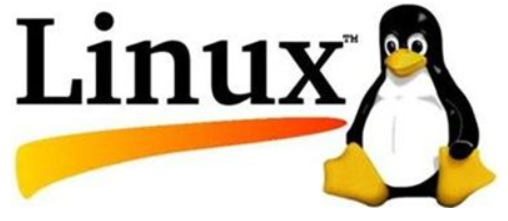

Linux是一套免费使用和自由传播的操作系统。说到操作系统，大家比较熟知的应该就是Windows和MacOS操作系统，我们今天所学习的Linux也是一款操作系统。

我们作为javaEE开发工程师，将来在企业中开发时会涉及到很多的数据库、中间件等技术，比如MySQL、Redis、MQ等技术，而这些应用软件大多都是需要安装在Linux系统中使用的。我们做为开发人员，是需要通过远程工具连接Linux操作系统，然后来操作这些软件的。而且一些小公司，可能还需要我们自己在服务器上安装这些软件。

所以，不管从企业的用人需求层面，还是个人发展需要层面来讲，我们作为服务端开发工程师，Linux的基本使用是我们必不可少的技能。

对于Linux的常用指令的学习，最好的学习方法就是：多敲

**讲义提示**

> 课程内容：

> - Linux概述

> - Linux常用命令

> - Linux软件安装

> - 项目部署

## Linux概述

> **补充｜权限意识。** Linux 中很多系统目录和服务操作需要 root 或 sudo 权限。日常开发尽量使用普通用户，只在安装软件、修改系统配置和管理服务时提升权限，并记录执行过的命令。

### 主流操作系统

不同领域的主流操作系统，主要分为以下这么几类： 桌面操作系统、服务器操作系统、移动设备操作系统、嵌入式操作系统。接下来，这几个领域中，代表性的操作系统是那些?

1). 桌面操作系统

> **讲义表格/演示内容**（原文以嵌入表格展示。）

2). 服务器操作系统

> **讲义表格/演示内容**（原文以嵌入表格展示。）

3). 移动设备操作系统

> **讲义表格/演示内容**（原文以嵌入表格展示。）

### Linux系统版本

Linux系统的版本分为两种，分别是： 内核版 和 发行版。

1). 内核版

- 由Linus Torvalds及其团队开发、维护

- 免费、开源

- 负责控制硬件

2). 发行版

- 基于Linux内核版进行扩展

- 由各个Linux厂商开发、维护

- 有收费版本和免费版本

我们使用Linux操作系统，实际上选择的是Linux的发行版本。在linux系统中，有各种各样的发行版本，具体如下：

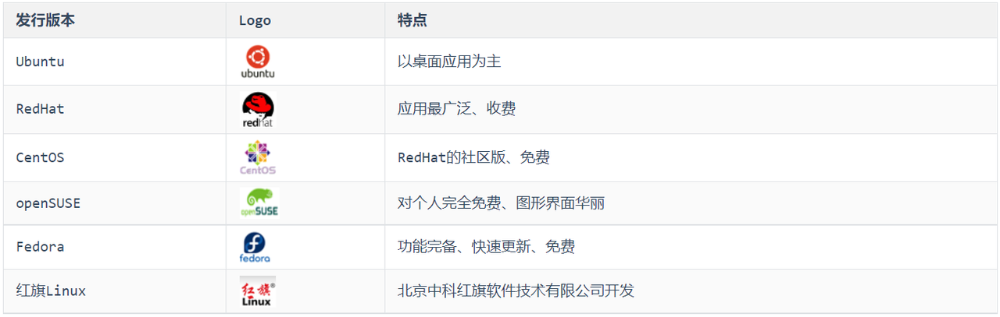

除了上述罗列出来的发行版，还有很多Linux发行版，这里，我们就不再一一列举了。

### 系统安装

> **补充｜虚拟机快照。** 完成基础系统安装和网络配置后创建快照，后续安装软件或修改配置前再创建阶段性快照，便于出错时恢复。

#### 安装方式

Linux系统的安装方式，主要包含以下两种：

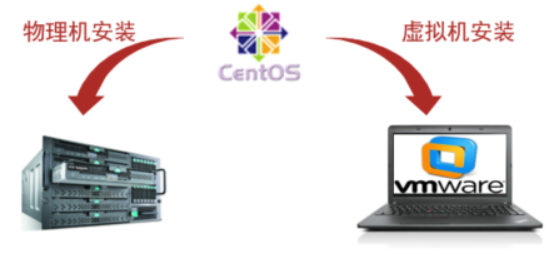

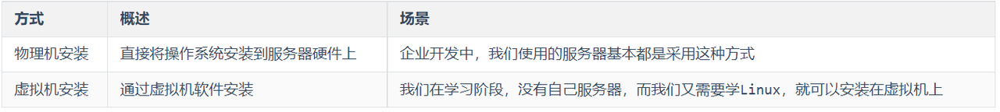

虚拟机（Virtual Machine）指通过软件模拟的具有完整硬件系统功能、运行在完全隔离环境中的完整计算机系统。常用虚拟机软件：

- VMWare

- VirtualBox

- VMLite WorkStation

- Qemu

- HopeddotVOS

那么我们就可以在课程中将Linux操作系统安装在虚拟机中，我们课上选择的虚拟机软件是VMware。

#### 安装VMware

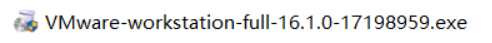

在我们的课程资料中提供了VMware的安装程序。找到课程资料中的 Vmware的安装包（exe文件），然后双击下一步下一步的安装即可。

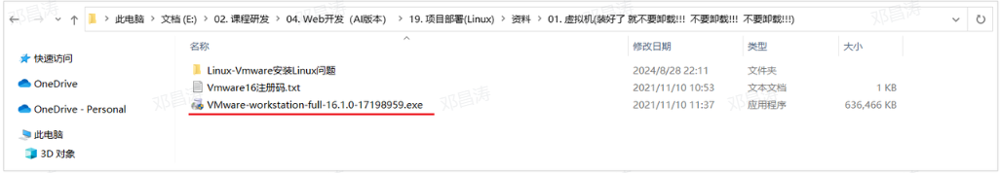

备注：如果之前安装过，就不用安装了。不要卸载！！！！ 不要卸载！！！！  不要卸载！！！！

安装步骤:

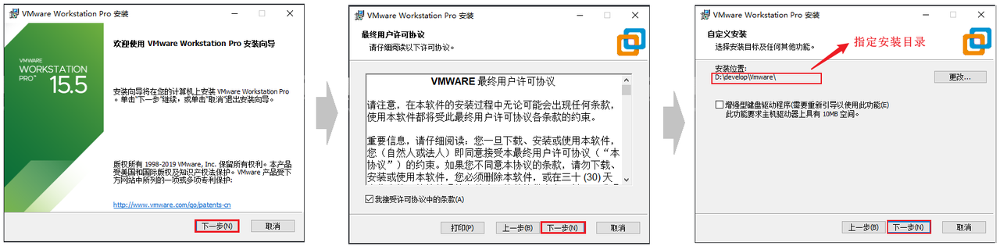

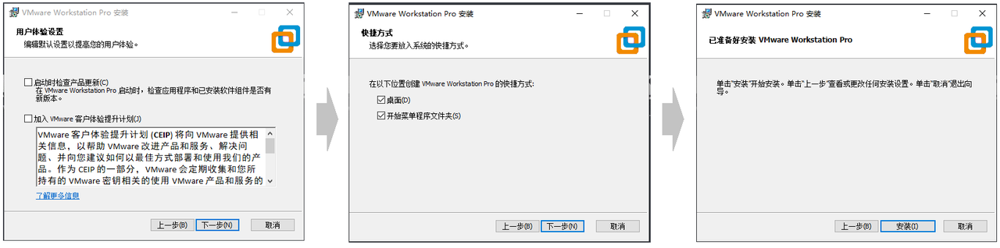

以上就是VMware在安装时的每一步操作，基本上就是点击 "下一步" 一直进行安装。

#### 挂载Linux系统

1). 打开Vmware虚拟机，打开 编辑 -> 虚拟网络编辑器(N)...

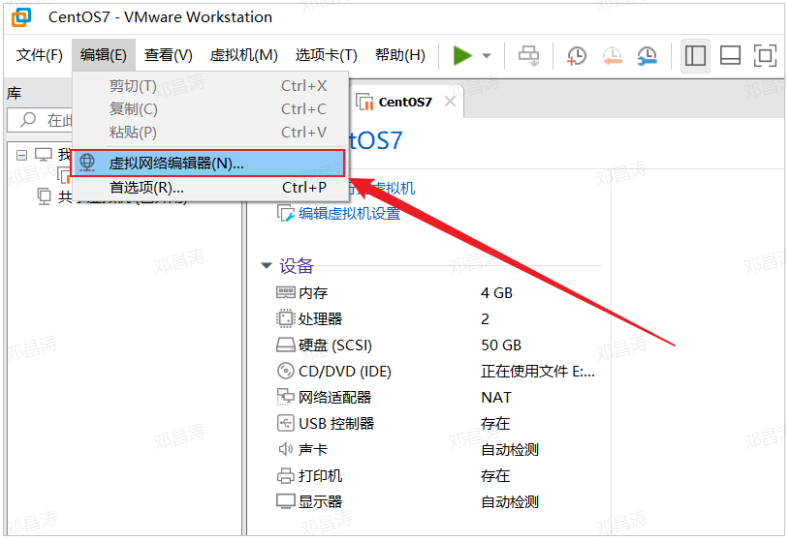

选择 NAT模式，然后选择右下角的 更改设置。

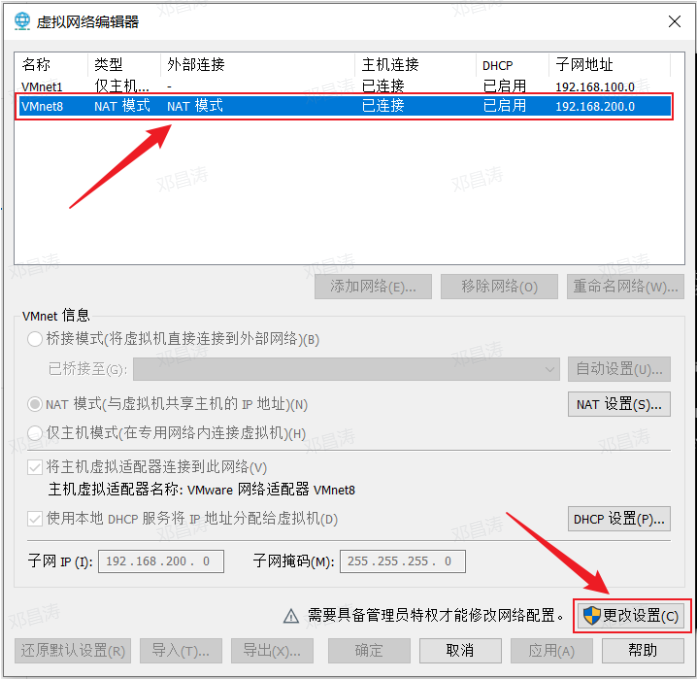

设置子网IP为 192.168.100.0，然后选择 应用 -> 确定。

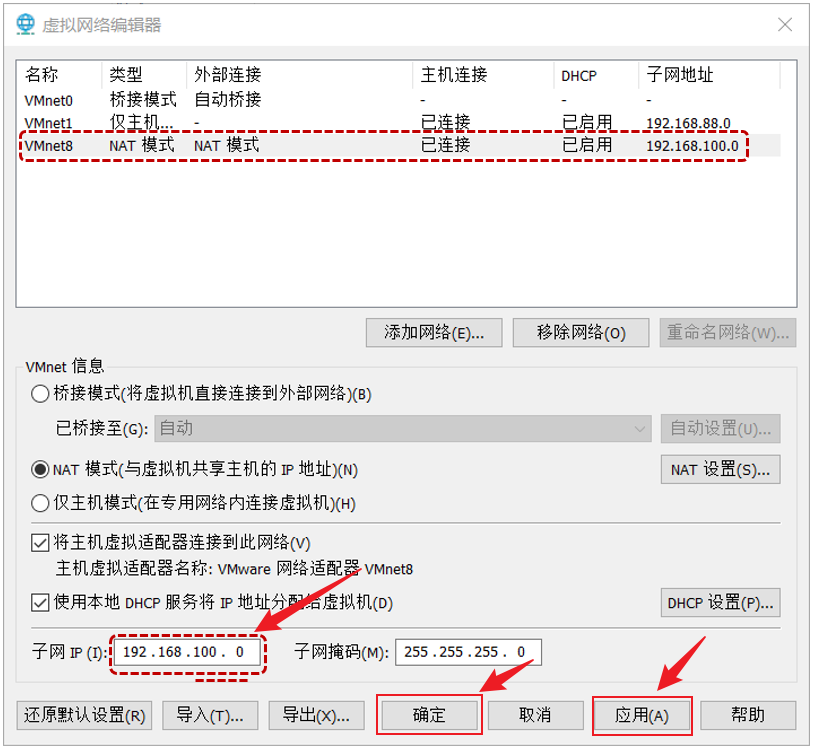

2). 解压 资料/Linux镜像/CentOS7-1.zip 到一个比较大的磁盘中 (没有中文的目录)。

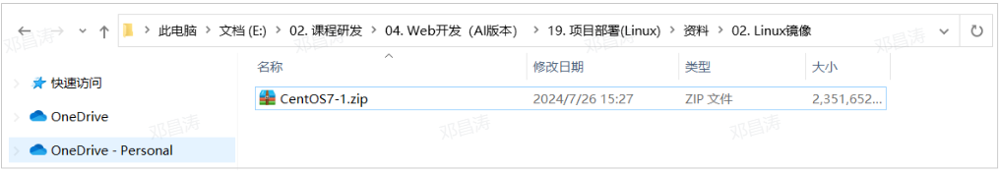

3). 打开解压目录，双击 .vmx 文件，选择以 Vmware Workstation 打开这个文件。

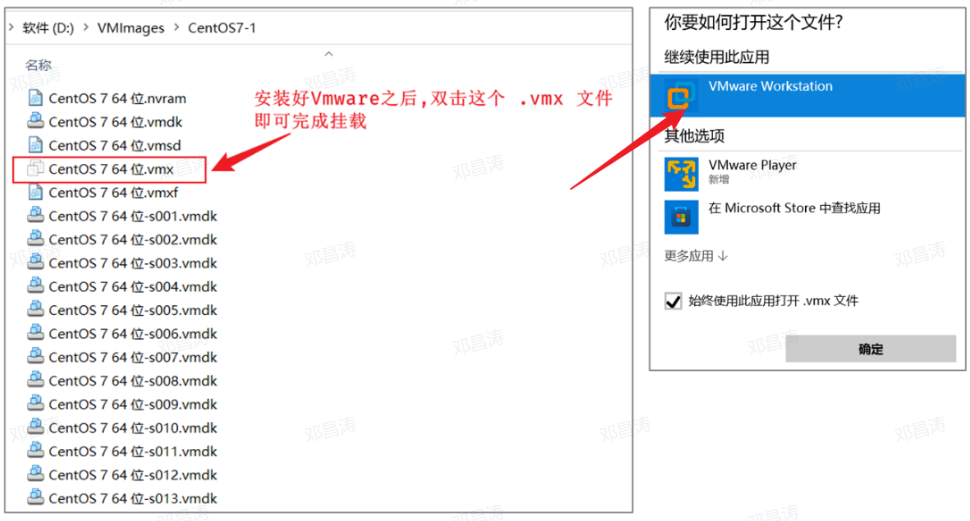

4). 挂载完毕之后，启动Linux服务器。

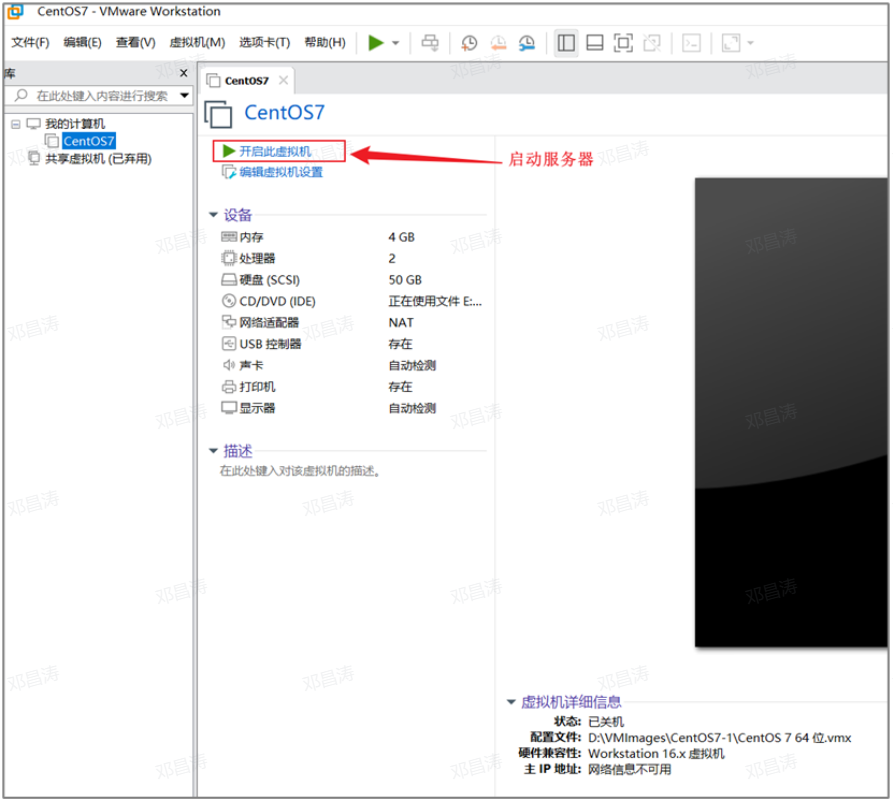

启动过程中，如果出现如下界面，选择 我已移动该虚拟机。

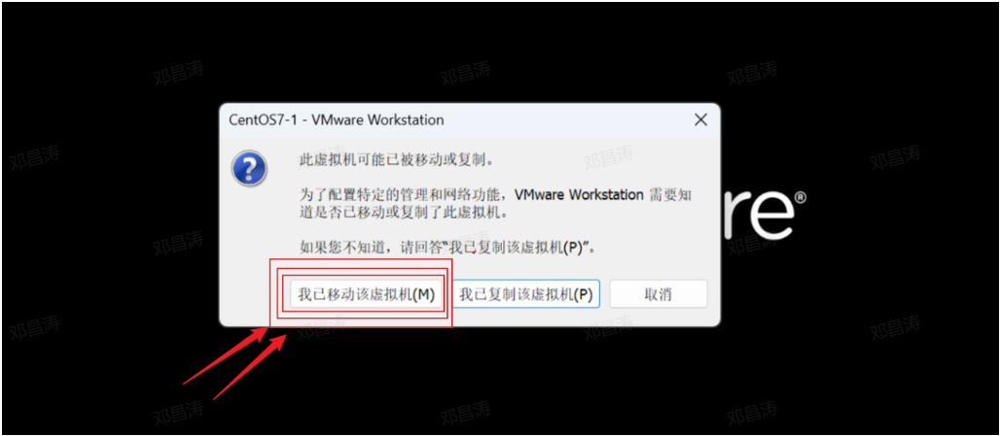

5). 启动完毕之后，登录服务器。 输入用户名：root，密码：1234  （注意：linux系统输入密码是不显示的，输入完毕，回车即可登录）

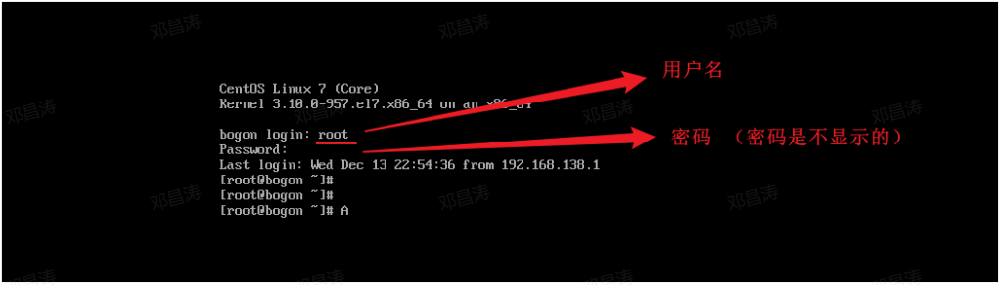

### 安装SSH连接工具

> **补充｜连接安全。** SSH 连接时确认服务器 IP、端口和用户，生产环境优先使用密钥认证并限制来源 IP；不要把密码直接写进脚本或聊天记录。

#### SSH连接工具介绍

Linux已经安装并且配置好了，接下来我们要来学习Linux的基本操作指令。而在学习之前，我们还需要做一件事情，由于我们企业开发时，Linux服务器一般都是在远程的机房部署的，我们要操作服务器，不会每次都跑到远程的机房里面操作，而是会直接通过SSH连接工具进行连接操作。

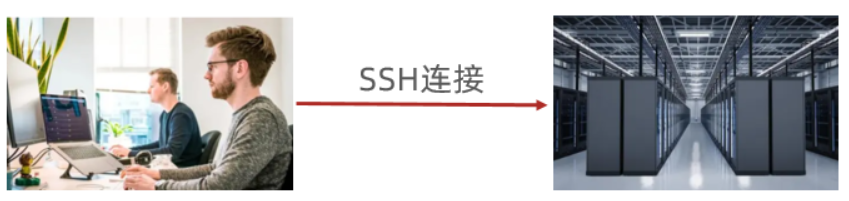

SSH（Secure Shell），建立在应用层基础上的安全协议。常用的SSH连接工具:

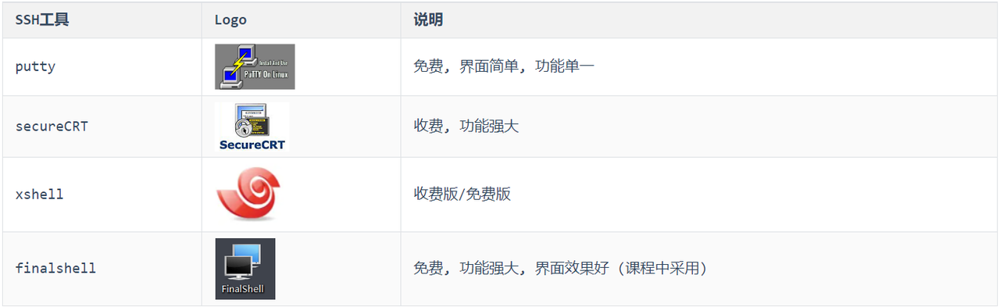

#### FinalShell安装

在课程资料中，提供了finalShell的安装包（"资料/03. 远程连接工具"）。

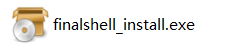

双击.exe文件，然后进行正常的安装即可。

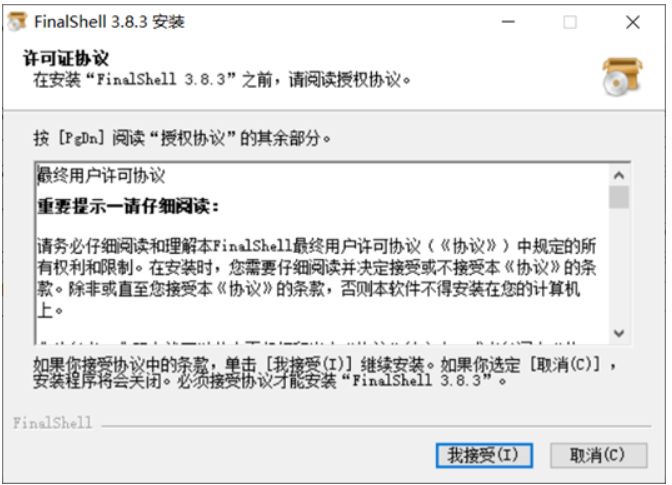

#### 连接Linux

- 打开FinalShell，选择SSH连接。

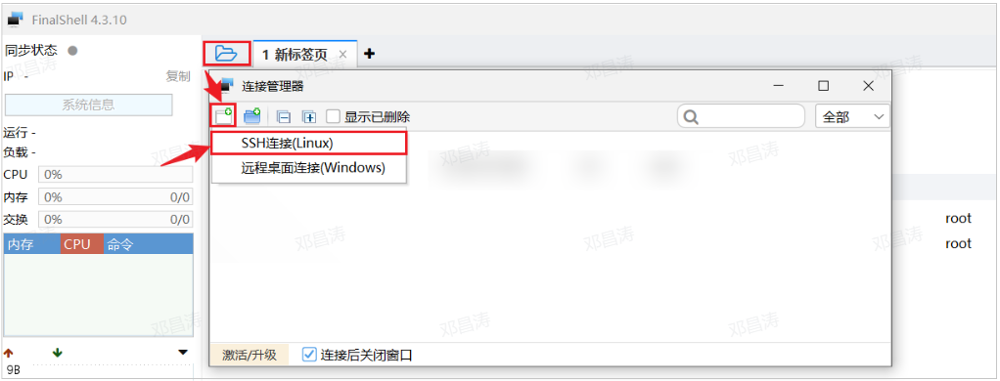

- 连接服务器，输入服务器的信息，IP固定的：192.168.100.128，用户名：root，密码：1234

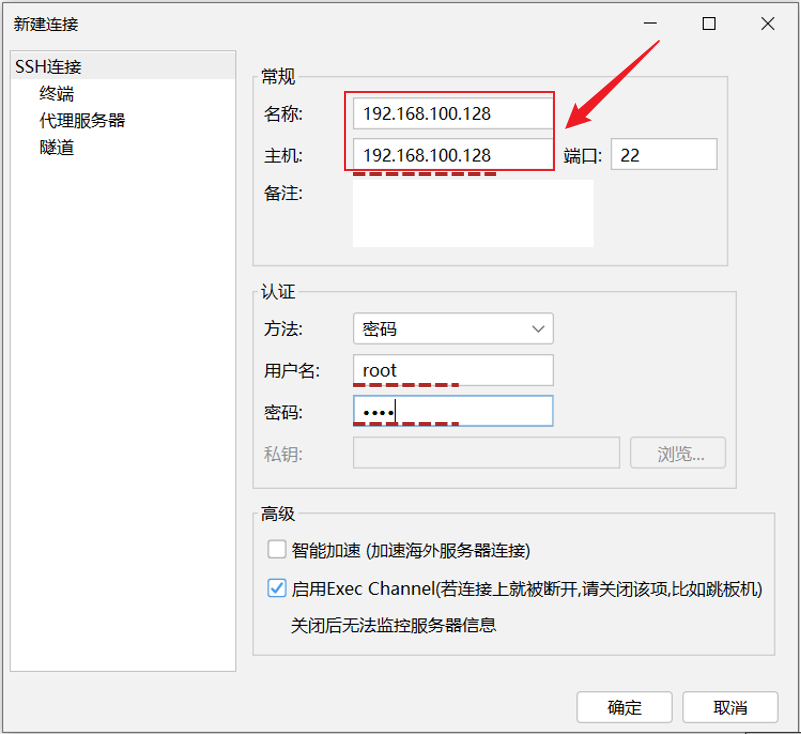

- 配置完毕后,双击即可连接服务器。

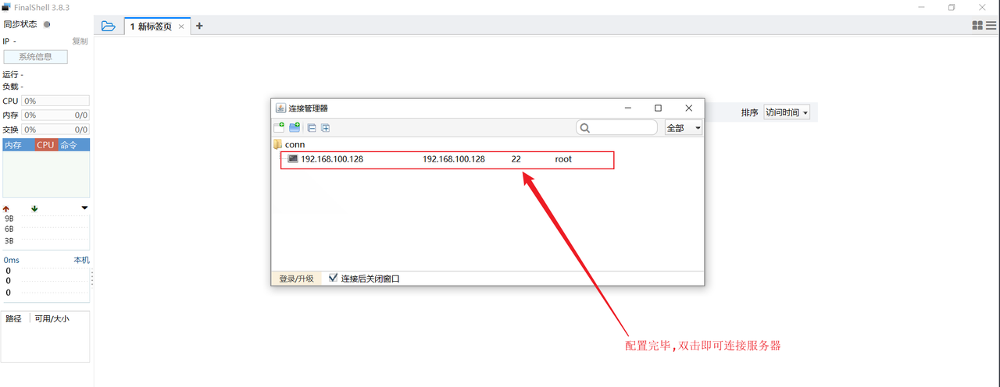

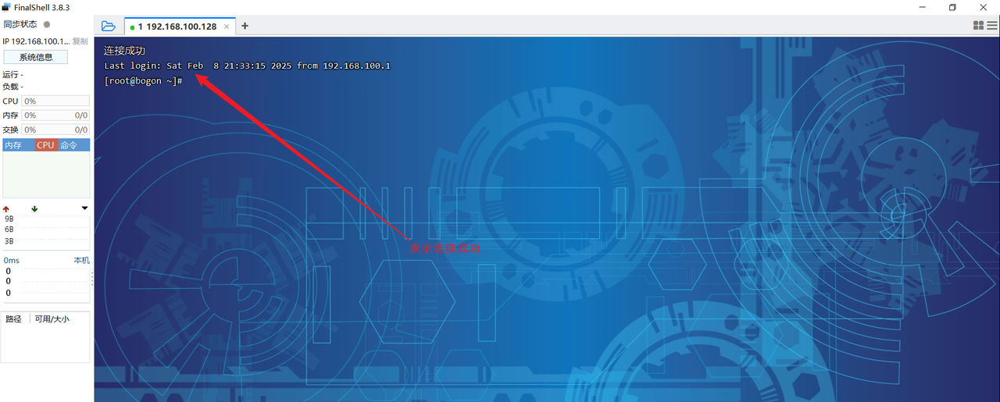

### 目录结构

> **补充｜目录定位。** 配置通常在 `/etc`，日志常在 `/var/log`，用户目录在 `/home`，第三方程序可以放在 `/opt`。部署时把应用、日志和配置分开，便于备份与排障。

登录到Linux系统之后，我们需要先来熟悉一下Linux的目录结构。在Linux系统中，也是存在目录的概念的，但是Linux的目录结构和Windows的目录结构是存在比较多的差异的 在Windows目录下，是一个一个的盘符(C盘、D盘、E盘)，目录是归属于某一个盘符的。Linux系统中的目录有以下特点：

- / 是所有目录的顶点

- 目录结构像一颗倒挂的树

Linux 和 Windows的目录结构对比:

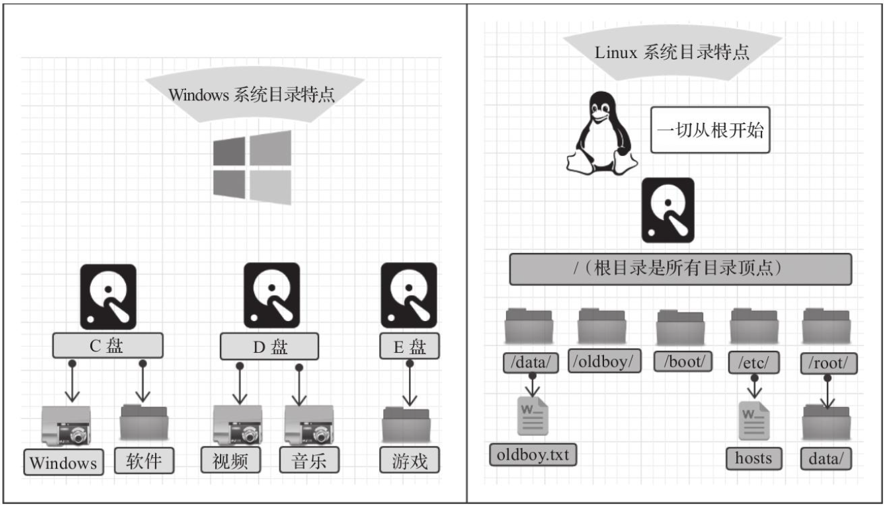

Linux的目录结构，如下：

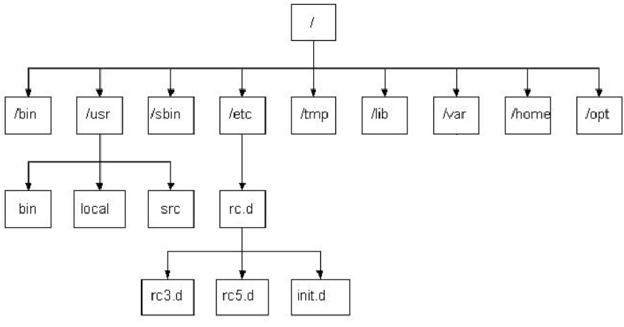

根目录 / 下各个目录的作用及含义说明:

> **讲义表格/演示内容**（原文以嵌入表格展示。）

## Linux常用命令

> **补充｜命令可恢复。** 执行删除、覆盖和移动命令前先用 `pwd`、`ls` 确认当前路径；对生产环境命令保留历史记录，必要时先做备份。

### Linux命令初体验

- Linux 命令格式：command [-options] [parameter]

- 说明：

- command：命令名

- [-options]：选项，可用来对命令进行控制，也可以省略 （可选）

- [parameter]：参数，可以是零个、一个或多个（可选）

- 例如：

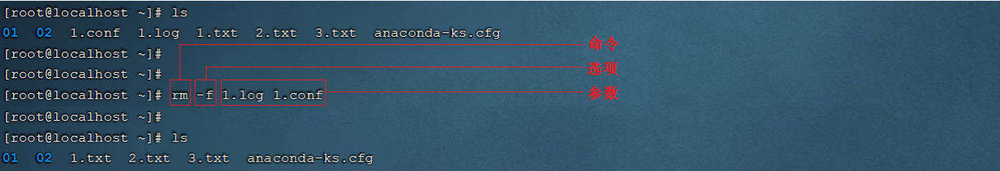

**讲义提示**

> 使用技巧：

> - Tab键自动补全

> - 连续两次Tab键，给出操作提示

> - 使用上下箭头快速调出曾经使用过的命令

> - 使用clear命令或Ctrl+l快捷键实现清屏

### 目录操作命令

> **补充｜相对路径与绝对路径。** 脚本和文档中优先使用明确的绝对路径；在交互式操作中使用相对路径时，先确认当前工作目录，避免误操作。

#### ls

**讲义提示**

> - 作用: 显示指定目录下的内容

> - 语法: ls [-al] [dir]

> - 说明:

> -a 显示所有文件及目录 (. 开头的隐藏文件也会列出)

> -l 除文件名称外，同时将文件型态(d表示目录，-表示文件)、权限、拥有者、文件大小等信息详细列出

> - 注意:

> 由于我们使用ls命令时经常需要加入-l选项，所以Linux为 ls -l 命令提供了一种简写方式，即 ll

> - 常见用法:

> ls -al           查看当前目录的所有文件及目录详细信息

> ls -al /etc  查看/etc目录下所有文件及目录详细信息

> ll                 查看当前目录文件及目录的详细信息

操作示例:

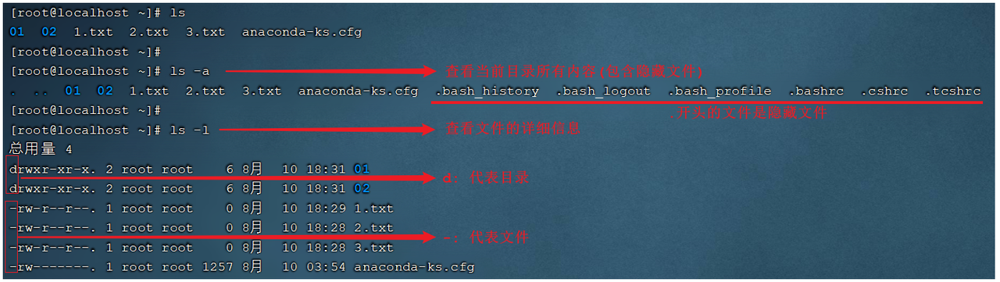

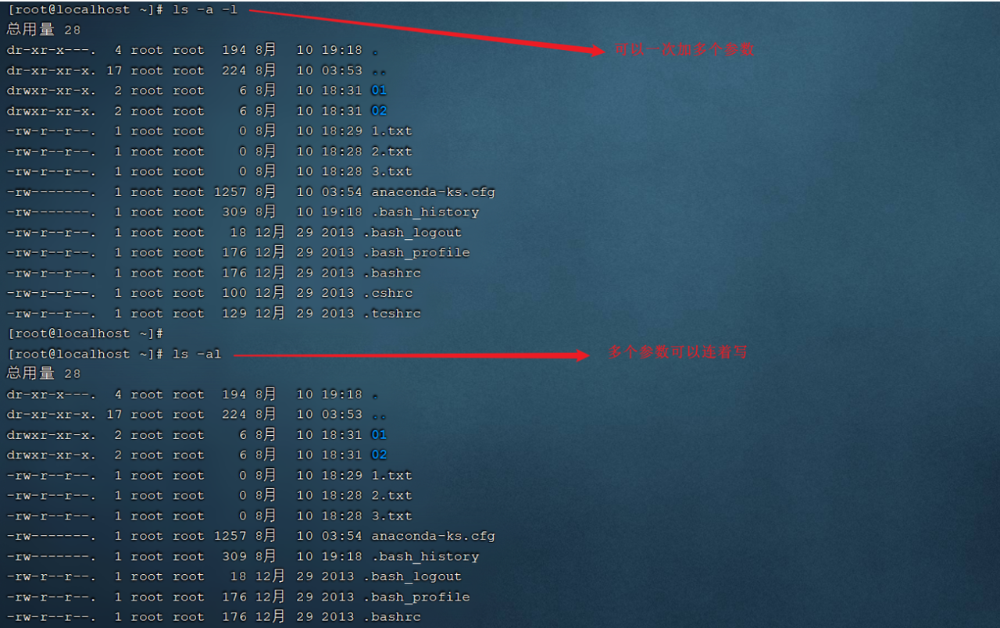

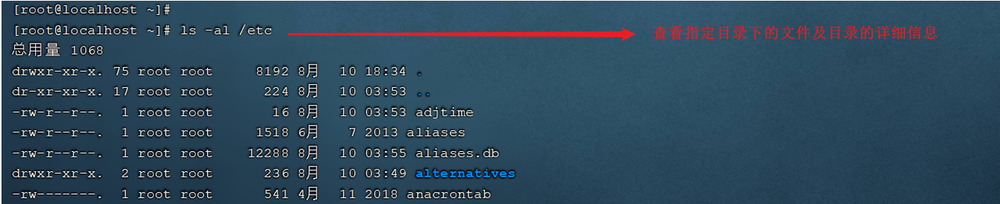

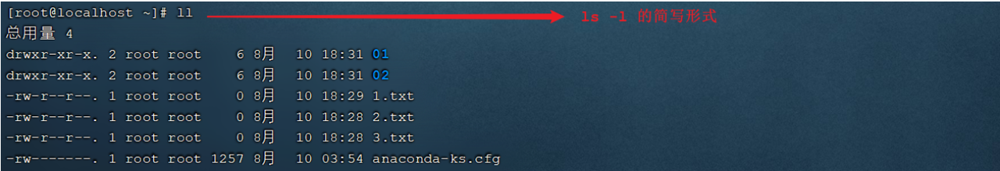

#### cd

**讲义提示**

> - 作用: 用于切换当前工作目录，即进入指定目录

> - 语法: cd [dirName]

> - 特殊说明:

> ~        表示用户的home目录

> .         表示目前所在的目录

> ..        表示目前目录位置的上级目录

> - 举例:

> cd         ..                切换到当前目录的上级目录

> cd         ~                切换到用户的home目录

> cd         /usr/local     切换到/usr/local目录

> - 备注:

> 用户的home目录

> root用户        /root

> 其他用户        /home/xxx

操作示例:

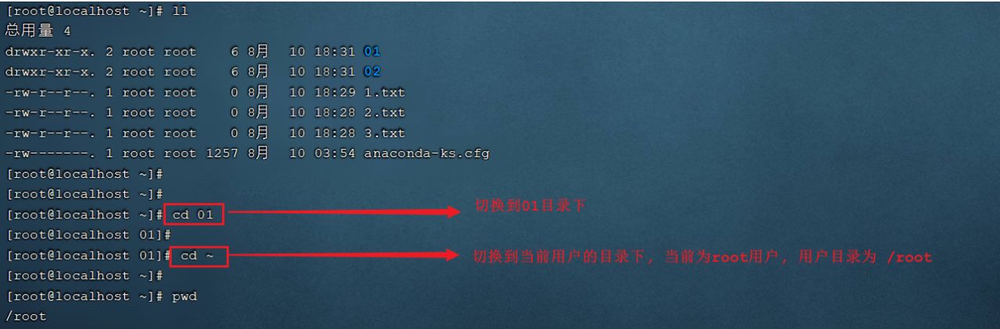

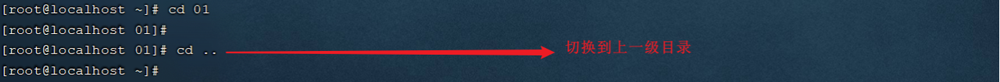

cd .. 切换到当前目录位置的上级目录; 可以通过 cd ../.. 来切换到上级目录的上级目录。

#### mkdir

**讲义提示**

> - 作用: 创建目录

> - 语法: mkdir [-p] dirName

> - 说明:

> -p: 确保目录名称存在，不存在的就创建一个。通过此选项，可以实现多层目录同时创建

> - 举例:

> mkdir itcast  在当前目录下，建立一个名为itcast的子目录

> mkdir -p itcast/test   在工作目录下的itcast目录中建立一个名为test的子目录，若itcast目录不存在，则建立一个

操作演示:

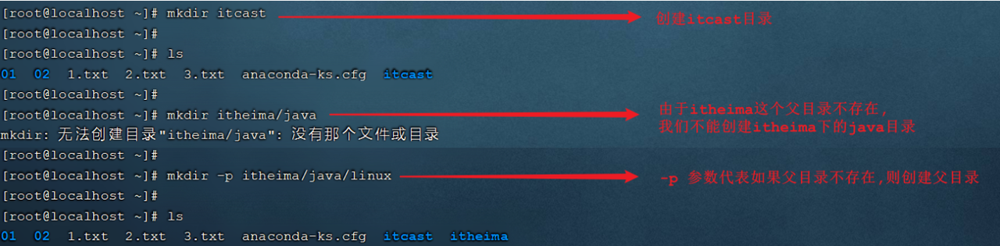

#### rm

**讲义提示**

> - 作用: 删除文件或者目录

> - 语法: rm [-rf] name

> - 说明:

> -r: 将目录及目录中所有文件（目录）逐一删除，即递归删除

> -f: 无需确认，直接删除

> - 举例:

> rm -r itcast/    删除名为itcast的目录和目录中所有文件，删除前需确认

> rm -rf itcast/    无需确认，直接删除名为itcast的目录和目录中所有文件

> rm -f hello.txt   无需确认，直接删除hello.txt文件

操作示例:

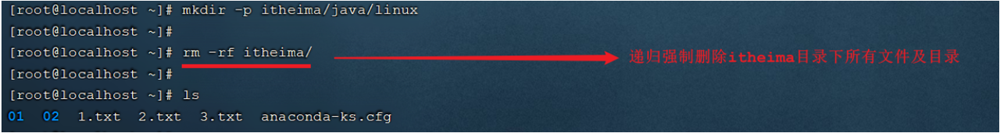

注意: 对于 rm -rf xxx 这样的指令，在执行的时候，一定要慎重，确认无误后再进行删除，避免误删。

### 文件操作命令

> **补充｜日志读取。** `tail -f` 适合跟踪实时日志，退出使用 Ctrl+C；查看大文件优先使用 `less` 或 `more`，避免一次性输出大量内容影响终端。

#### cat

**讲义提示**

> - 作用: 用于显示文件内容

> - 语法: cat [-n] fileName

> - 说明:

> -n: 由1开始对所有输出的行数编号

> - 举例:

> cat /etc/profile                查看/etc目录下的profile文件内容

操作演示:

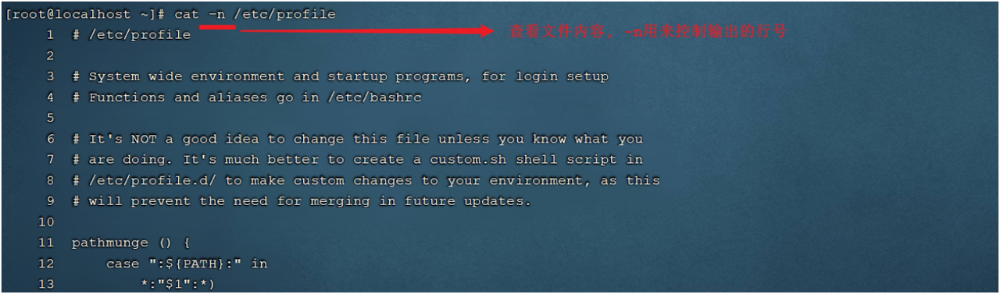

cat 指令会一次性查看文件的所有内容，如果文件内容比较多，这个时候查看起来就不是很方便了，这个时候我们可以通过一个新的指令more。

#### more

**讲义提示**

> - 作用: 以分页的形式显示文件内容

> - 语法: more fileName

> - 操作说明:

> - 回车键               向下滚动一行

> - 空格键               向下滚动一屏

> - b                       返回上一屏

> - q或者Ctrl+C        退出more

> - 举例：

> - more /etc/profile                以分页方式显示/etc目录下的profile文件内容

操作示例：

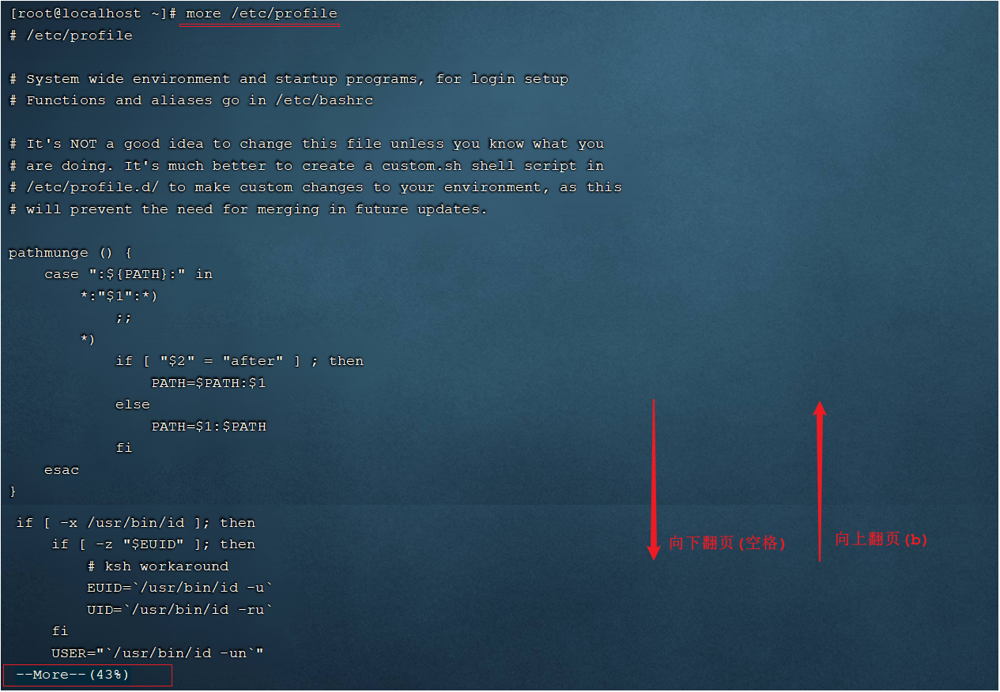

当我们在查看一些比较大的文件时，我们可能需要经常查询文件尾部的数据信息，那这个时候如果文件很大，我们要一直向下翻页，直到最后一页，去看最新添加的数据，这种方式就比较繁琐了，此时，我们可以借助于tail指令。

#### head

**讲义提示**

> - 作用：查看文件开头的内容

> - 语法：head [-n] fileName

> - 说明:

> - -n ：输出文件开头的n行内容

> - 举例：

> - head 1.log  默认显示1.log文件开头的10行内容

> - head -20 1.log  显示1.log文件开头的20行内容

#### tail

**讲义提示**

> - 作用: 查看文件末尾的内容

> - 语法: tail [-f] fileName

> - 说明:

> -f : 动态读取文件末尾内容并显示，通常用于日志文件的内容输出

> - 举例:

> - tail /etc/profile                显示/etc目录下的profile文件末尾10行的内容

> - tail -20 /etc/profile           显示/etc目录下的profile文件末尾20行的内容

> - tail -f /itcast/my.log          动态读取/itcast目录下的my.log文件末尾内容并显示

操作示例：

A. 默认查询文件尾部10行记录

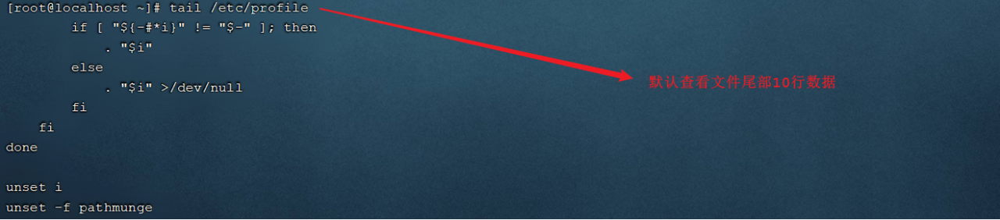

B. 可以通过指定参数设置查询尾部指定行数的数据

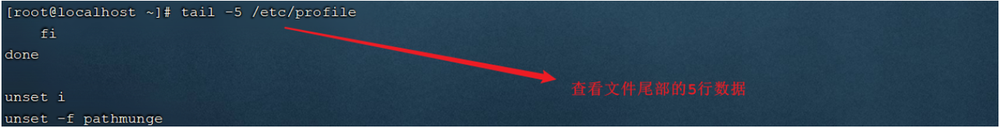

C. 动态读取文件尾部的数据

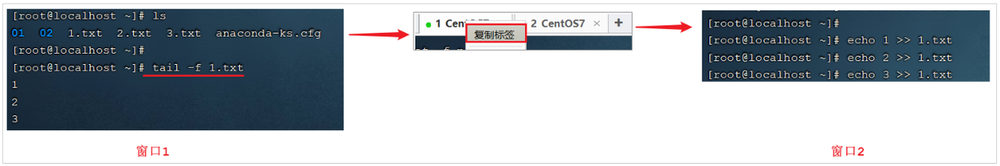

在窗口1中执行指令 tail -f 1.txt 动态查看文件尾部的数据。然后在顶部的标签中右键选择 "复制标签"，打开新的窗口2 , 此时再新打开的窗口2中执行指令 echo 1 >> 1.txt , 往1.txt文件尾部追加内容，然后我们就可以在窗口1中看到最新的文件尾部的数据。

如果我们不想查看文件尾部的数据了，可以直接使用快捷键 Ctrl+C ， 结束当前进程。

### 拷贝移动命令

> **补充｜覆盖风险。** `cp` 和 `mv` 可能覆盖目标文件，重要配置修改前先复制一份带时间戳的备份，并用 `diff` 核对变更。

#### cp

**讲义提示**

> - 作用: 用于复制文件或目录

> - 语法: cp [-r] source dest

> - 说明:

> -r: 如果复制的是目录需要使用此选项，此时将复制该目录下所有的子目录和文件

> - 举例:

> cp hello.txt itcast/            将hello.txt复制到itcast目录中

> cp hello.txt ./hi.txt           将hello.txt复制到当前目录，并改名为hi.txt

> cp -r itcast/ ./itheima/            将itcast目录和目录下所有文件复制到itheima目录下

> cp -r itcast/\* ./itheima/                  将itcast目录下所有文件复制到itheima目录下

操作示例:

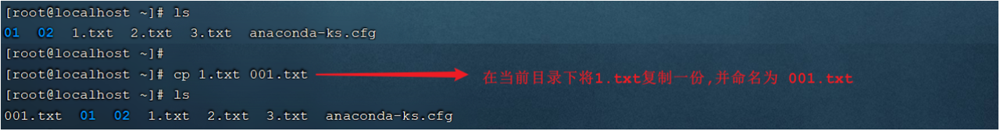

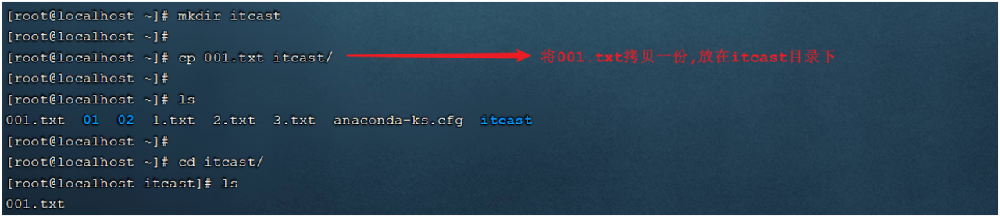

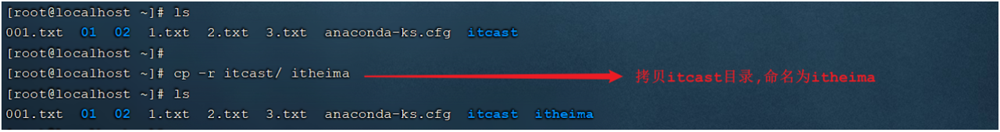

如果拷贝的内容是目录，需要加上参数 -r

#### mv

**讲义提示**

> - 作用: 为文件或目录改名、或将文件或目录移动到其它位置

> - 语法: mv source dest

> - 举例:

> - mv hello.txt hi.txt                   将hello.txt改名为hi.txt

> - mv hi.txt itheima/                   将文件hi.txt移动到itheima目录中

> - mv hi.txt itheima/hello.txt        将hi.txt移动到itheima目录中，并改名为hello.txt

> - mv itcast/ itheima/                 如果itheima目录不存在，将itcast目录改名为itheima

> - mv itcast/ itheima/                 如果itheima目录存在，将itcast目录移动到itheima目录中

操作示例:

mv 命令既能够改名，又可以移动，具体是改名还是移动,系统会根据我们输入的参数进行判定(如果第二个参数dest是一个已存在的目录,将执行移动操作,其他情况都是改名)

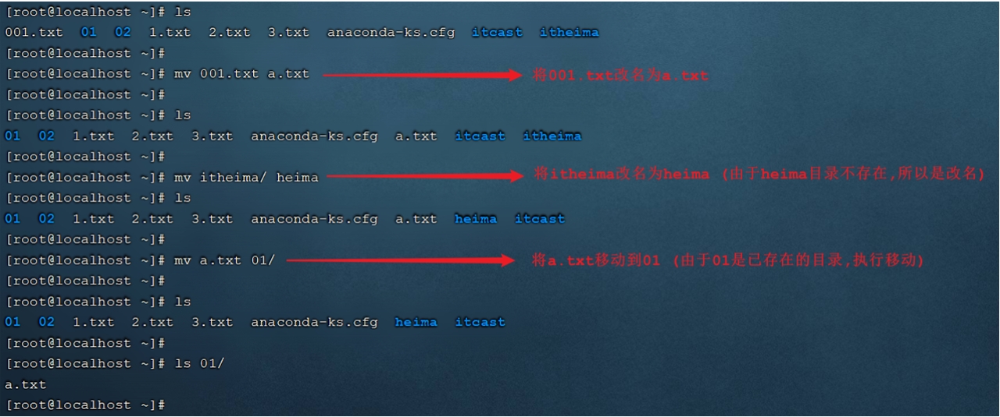

### 打包压缩命令

> **补充｜归档策略。** 归档前确认目录和排除项，解压到独立目录后再覆盖线上文件。备份文件应包含版本号或日期，并定期验证能否恢复。

**讲义提示**

> - 作用: 对文件进行打包、解包、压缩、解压

> - 语法: tar  [-zcxvf]  fileName  [files]

> 包文件后缀为.tar表示只是完成了打包，并没有压缩

> 包文件后缀为.tar.gz表示打包的同时还进行了压缩

> - 说明:

> - -z: z代表的是gzip，通过gzip命令处理文件，gzip可以对文件压缩或者解压

> - -c: c代表的是create，即创建新的包文件

> - -x: x代表的是extract，实现从包文件中还原文件

> - -v: v代表的是verbose，显示命令的执行过程

> - -f: f代表的是file，用于指定包文件的名称

> - 举例：

> - 打包

> - tar -cvf hello.tar ./\*                                  将当前目录下所有文件打包，打包后的文件名为hello.tar

> - tar -zcvf hello.tar.gz ./\*                          将当前目录下所有文件打包并压缩，打包后的文件名为hello.tar.gz

> - 解包

> - tar -xvf hello.tar                                          将hello.tar文件进行解包，并将解包后的文件放在当前目录

> - tar -zxvf hello.tar.gz                                  将hello.tar.gz文件进行解压，并将解压后的文件放在当前目录

> - tar -zxvf hello.tar.gz -C /usr/local     将hello.tar.gz文件进行解压，并将解压后的文件放在/usr/local目录

操作示例:

A. 打包

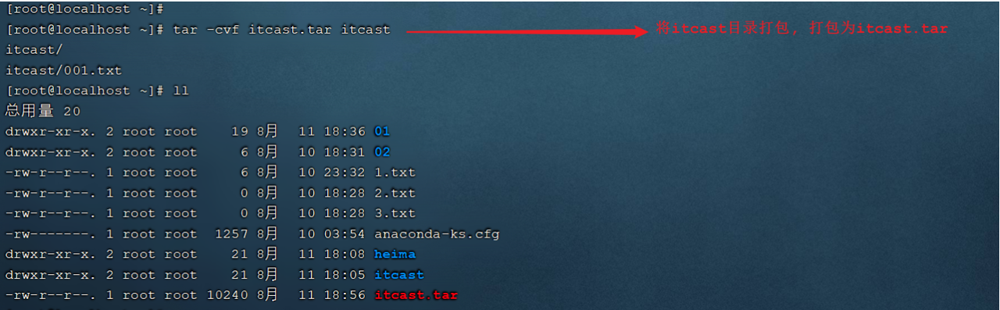

B. 打包并压缩

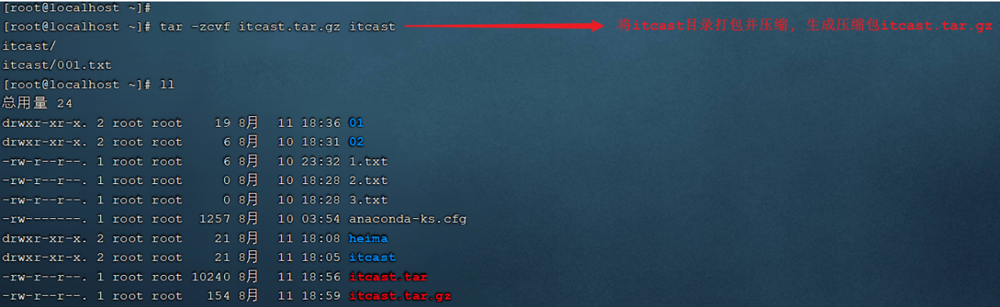

C. 解包

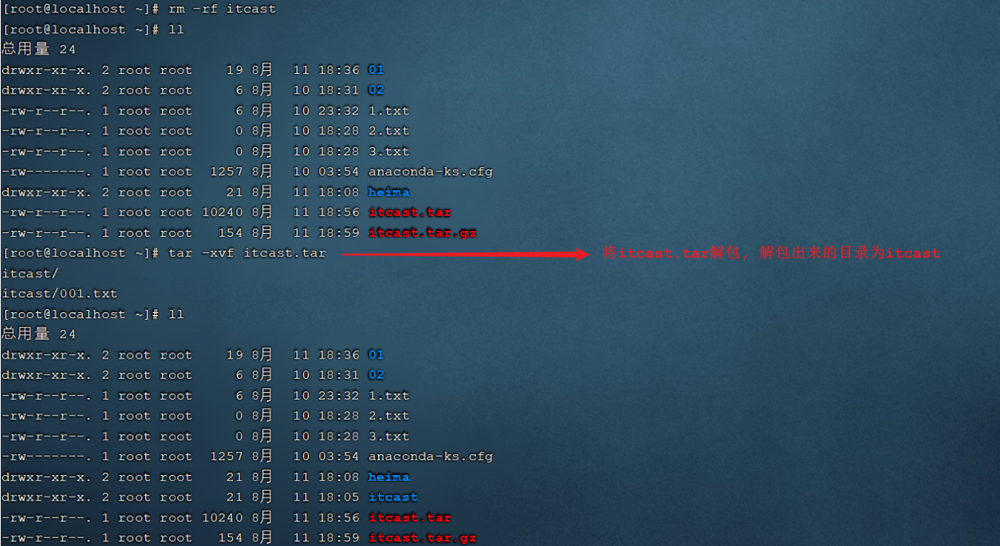

D. 解压

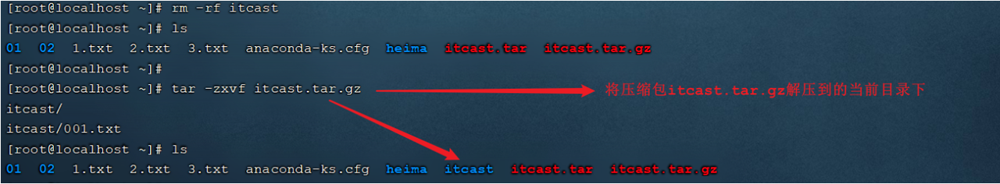

解压到指定目录,需要加上参数 -C

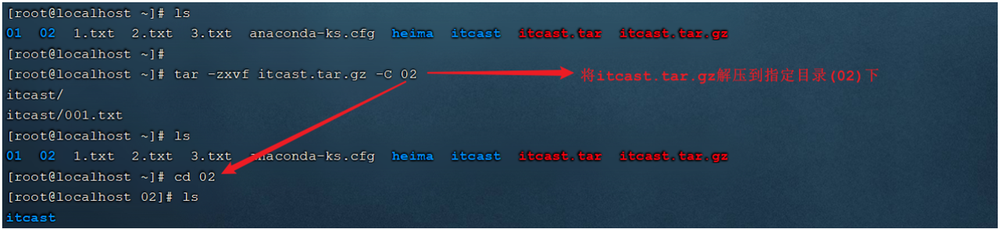

### 文本编辑命令

> **补充｜Vim 最小闭环。** 记住 `i` 进入插入模式、Esc 返回普通模式、`:wq` 保存退出、`:q!` 放弃退出即可完成多数配置修改；编辑后用 `cat` 或 `grep` 复核。

文本编辑的命令，主要包含两个: vi 和 vim，两个命令的用法类似，我们课程中主要讲解vim的使用。

#### vi & vim介绍

- 作用: vi命令是Linux系统提供的一个文本编辑工具，可以对文件内容进行编辑，类似于Windows中的记事本

- 语法: vi fileName

- 说明:

- 1). vim是从vi发展来的一个功能更加强大的文本编辑工具，编辑文件时可以对文本内容进行着色，方便我们对文件进行编辑处理，所以实际工作中vim更加常用。

- 2). 要使用vim命令，需要我们自己完成安装。可以使用下面的命令来完成安装：yum install vim

#### vim安装

命令： yum install vim

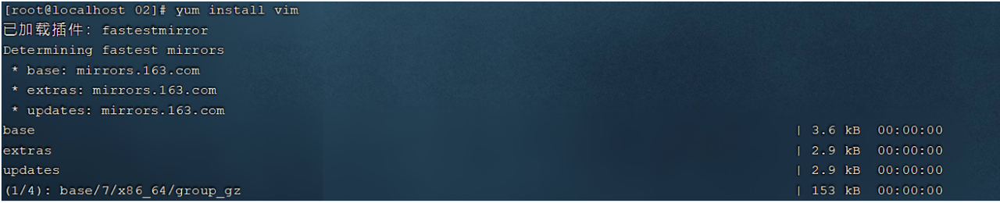

安装过程中，会有确认提示，此时输入 y，然后回车，继续安装：

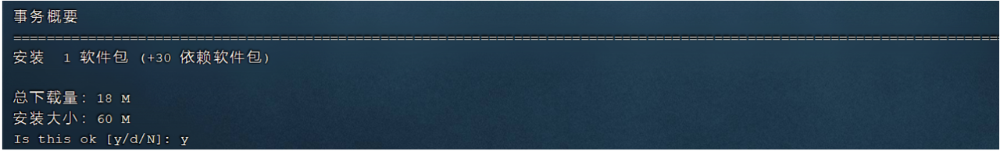

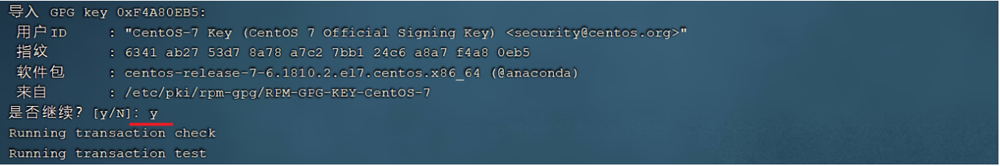

#### vim使用

- 作用: 对文件内容进行编辑，vim其实就是一个文本编辑器

- 语法: vim fileName

- 说明:

- 1). 在使用vim命令编辑文件时，如果指定的文件存在则直接打开此文件。如果指定的文件不存在则新建文件。

- 2). vim在进行文本编辑时共分为三种模式，分别是 命令模式（Command mode），插入模式（Insert mode）和底行模式（Last line mode）。这三种模式之间可以相互切换。我们在使用vim时一定要注意我们当前所处的是哪种模式。

- 三种模式:

- 命令模式

- A. 命令模式下可以查看文件内容、移动光标（上下左右箭头、gg、G)

- B. 通过vim命令打开文件后，默认进入命令模式

- C. 另外两种模式需要首先进入命令模式，才能进入彼此

| 列1 | 列2 |
| --- | --- |
| 命令模式指令 | 含义 |
| gg | 定位到文本内容的第一行 |
| G | 定位到文本内容的最后一行 |
| dd | 删除光标所在行的数据 |
| ndd | 删除当前光标所在行及之后的n行数据 |
| u | 撤销操作 |
| i 或 a 或 o | 进入插入模式(进入后光标所处的位置不同而已) |

- 插入模式

- A. 插入模式下可以对文件内容进行编辑

- B. 在命令模式下按下[i,a,o]任意一个，可以进入插入模式。进入插入模式后，下方会出现【insert】字样

- C. 在插入模式下按下ESC键，回到命令模式

- 底行模式

- A. 底行模式下可以通过命令对文件内容进行查找、显示行号、退出等操作

- B. 在命令模式下按下[:,/]任意一个，可以进入底行模式

- C. 通过/方式进入底行模式后，可以对文件内容进行查找

- D. 通过:方式进入底行模式后，可以输入wq（保存并退出）、q!（不保存退出）、set nu（显示行号）

| 列1 | 列2 |
| --- | --- |
| 底行模式指令 | 含义 |
| :wq | 保存并退出 |
| :q! | 不保存退出 |
| :set nu | 显示行号 |
| :set nonu | 取消行号显示 |
| :n | 定位到第n行，如 :10 就是定位到第10行 |

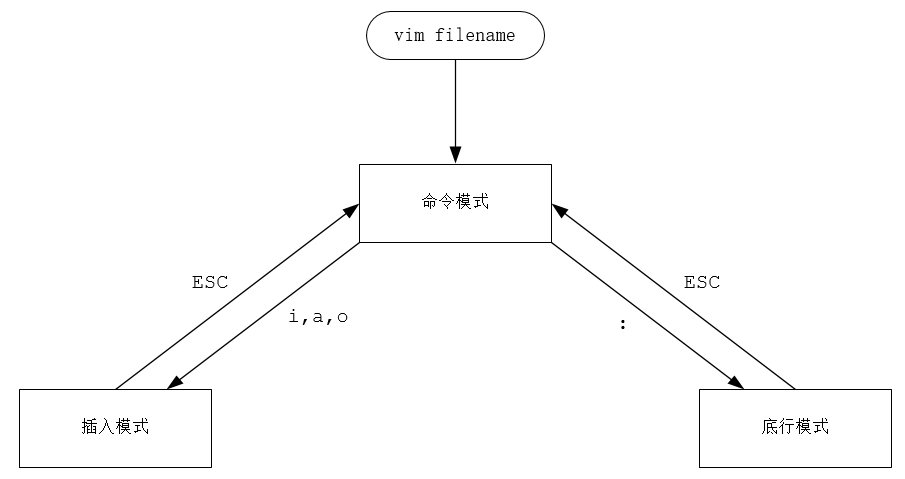

### 查找命令

> **补充｜组合查找。** `find` 负责按路径、名称和类型筛选文件，`grep` 负责查找文本内容。生产排障时可以先缩小目录，再用 `grep -n` 显示行号。

#### find

**讲义提示**

> - 作用: 在指定目录下查找文件

> - 语法: find dirName -option fileName

> - 举例:

> - find  .  –name "\*.java"                        在当前目录及其子目录下查找.java结尾文件

> - find  /itcast  -name "\*.java"             在/itcast目录及其子目录下查找.java结尾的文件

操作示例:

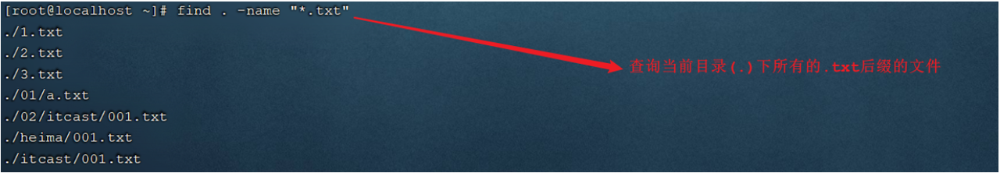

#### grep

**讲义提示**

> - 作用: 从指定文件中查找指定的文本内容

> - 语法: grep word fileName

> - 选项：

> - -i: 检索的关键字忽略(ignore)大小写

> - -n: 显示关键字所在的这一行的行号

> - -A: 输出关键字所在行及之后(After)的几行记录 (如:-A5 表示输出关键字所在行之后的5行记录)

> - -B: 输出关键字所在行及之前(Before)的几行记录 (如:-B5 表示输出关键字所在行之前的5行记录)

> - 举例:

> - grep Hello HelloWorld.java        查找HelloWorld.java文件中出现的Hello字符串的位置

> - grep hello \*.java                        查找当前目录中所有.java结尾的文件中包含hello字符串的位置

操作示例:

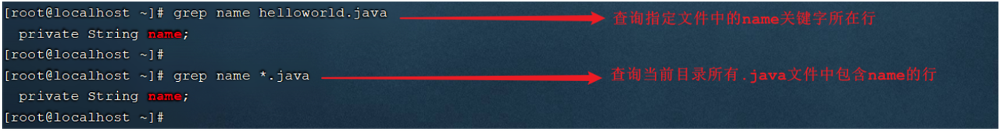

## 软件安装

> **补充｜包管理器。** 优先使用发行版的包管理器安装和升级软件，记录软件版本与配置文件位置；手动安装的压缩包要明确安装目录和卸载方式。

### 软件安装方式

在Linux系统中，安装软件的方式主要有四种，这四种安装方式的特点如下：

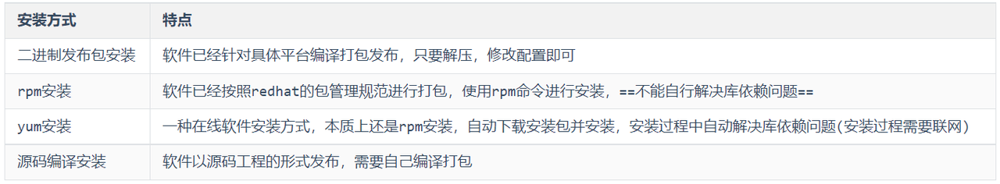

### 安装JDK

> **补充｜环境变量。** 配置 `JAVA_HOME` 后同时检查 `PATH`、`java -version` 和 `javac -version`，确保服务启动脚本使用的是预期 JDK，而不是系统中的其他版本。

上述我们介绍了Linux系统软件安装的四种形式，接下来我们就通过第一种(二进制发布包)形式来安装JDK。 JDK对应的二进制发布包，在课程资料中已经提供，如下：

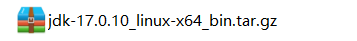

JDK具体安装步骤如下：

1). 上传安装包

使用FinalShell自带的上传工具将jdk的二进制发布包上传到Linux

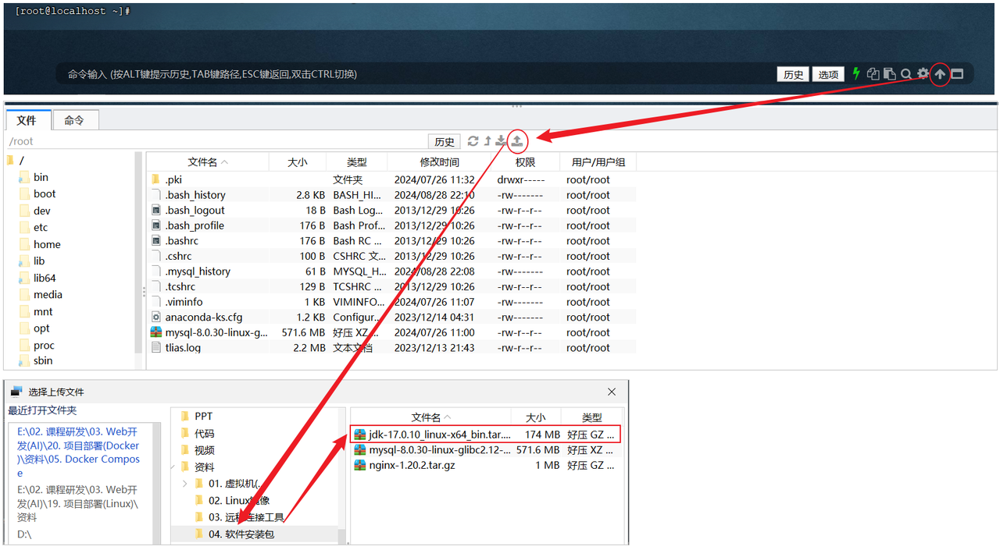

由于上述在进行文件上传时，选择的上传目录 /root，上传完毕后，我们执行指令 cd /root 切换到根目录下，查看上传的安装包。

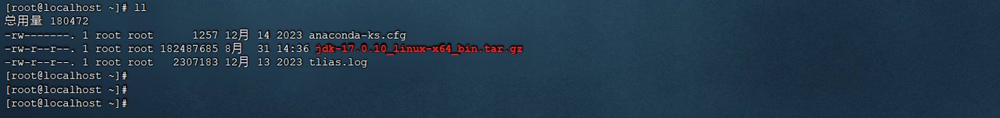

2). 解压安装包

执行如下指令，将上传上来的压缩包进行解压，并通过-C参数指定解压文件存放目录为 /usr/local。

```shell
tar -zxvf jdk-21_linux-x64_bin.tar.gz -C /usr/local/
```

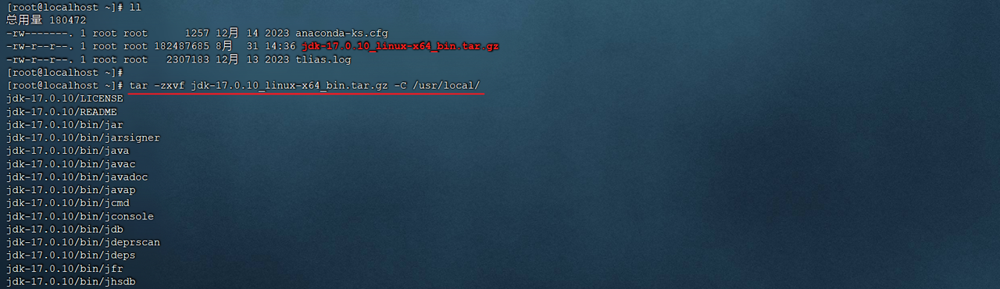

3). 配置环境变量

使用vim命令修改/etc/profile文件，在文件末尾加入如下配置

```shell
export JAVA_HOME=/usr/local/jdk-17.0.10
export PATH=$JAVA_HOME/bin:$PATH
```

具体操作指令如下:

```shell
1). 编辑/etc/profile文件，进入命令模式
    vim /etc/profile

2). 在命令模式中，输入指令 G ， 切换到文件最后
    G

3). 在命令模式中输入 i/a/o 进入插入模式，然后切换到文件最后一行
    i

4). 将上述的配置拷贝到文件中
    export JAVA_HOME=/usr/local/jdk-17.0.10
    export PATH=$JAVA_HOME/bin:$PATH
        
5). 从插入模式，切换到指令模式
    ESC
        
6). 按:进入底行模式，然后输入wq，回车保存
    :wq
```

4). 重新加载profile文件

为了使更改的配置立即生效，需要重新加载profile文件，执行命令:

```shell
source /etc/profile
```

5). 检查安装是否成功

```shell
java -version
```

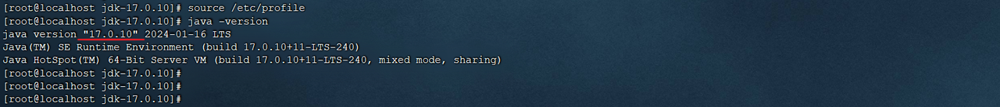

### 安装MySQL

> **补充｜数据库初始化。** 生产数据库使用独立账号和最小权限，修改默认密码并限制远程访问来源。部署前准备数据库备份和初始化脚本，验证字符集与时区配置。

#### MySQL安装

> **补充｜服务状态。** 安装后检查服务状态、监听端口和错误日志，确认开机自启配置符合服务器重启后的预期。

对于MySQL数据库的安装，我们将要使用前面讲解的第一种安装方式进行安装。

1). 准备工作

在安装MySQL数据库之前，我们需要先检查一下当前Linux系统中，是否安装的有MySQL的相关服务（很多linux安装完毕之后，自带了低版本的mysql的依赖包），如果有，先需要卸载掉，然后再进行安装。

A. 通过rpm相关指令，来查询当前系统中是否存在已安装的mysql软件包，执行指令如下：

- rpm -qa                                  查询当前系统中安装的所有软件

- rpm -qa | grep mysql            查询当前系统中安装的名称带mysql的软件

- rpm -qa | grep mariadb        查询当前系统中安装的名称带mariadb的软件

通过rpm -qa 查询到系统通过rpm安装的所有软件，太多了，不方便查看，所以我们可以通过管道符 | 配合着grep进行过滤查询。

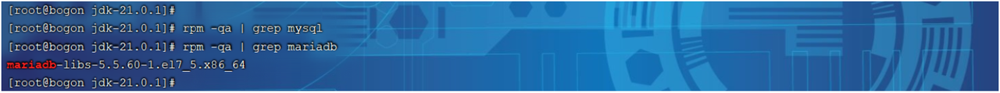

通过查询，我们发现在当前系统中存在mariadb数据库，是CentOS7中自带的，而这个数据库和MySQL数据库是冲突的，所以要想保证MySQL成功安装，需要卸载mariadb数据库。

**讲义提示**

> RPM：全称为 Red-Hat Package Manager，RPM软件包管理器，是红帽Linux用于管理和安装软件的工具。

B. 通过 rpm 相关指令，来卸载对应的组件，执行指令如下：

在rpm中，卸载软件的语法为：rpm -e --nodeps  软件名称

那么，我们就可以通过指令，卸载 mariadb，具体指令为： rpm -e --nodeps mariadb-libs-5.5.60-1.el7_5.x86_64

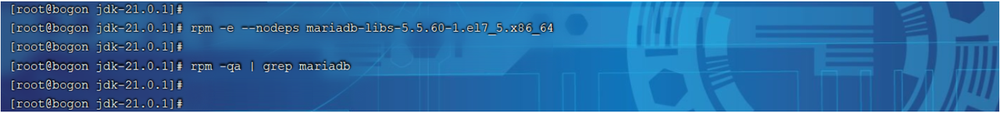

我们看到执行完毕之后， 再次查询 mariadb，就查不到了，因为已经被成功卸载了。

2). 将资料中提供的MySQL安装包上传到Linux并解压

A. 上传MySQL安装包

在课程资料中，提供的有MySQL的安装包 ，我们需要将该安装包上传到Linux系统的根目录 /root 下面。

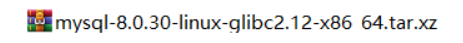

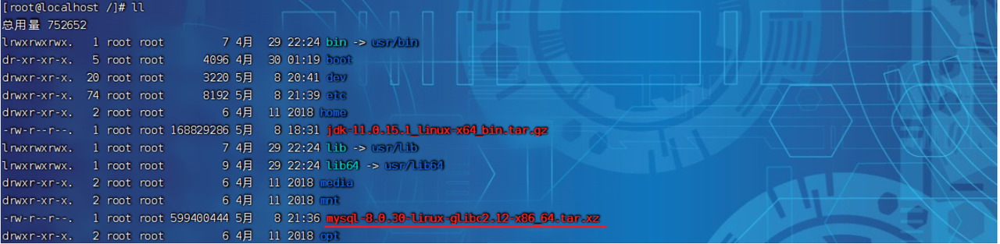

B. 解压到 当前目录

执行如下指令:

```powershell
tar -xvf mysql-8.0.30-linux-glibc2.12-x86_64.tar.xz
```

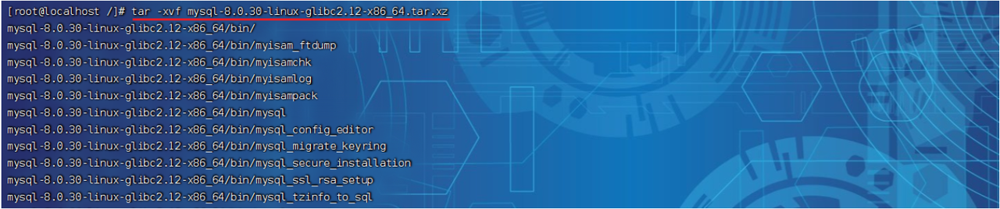

C. 将解压后的文件夹移动到 /usr/local 目录下， 并改名为 mysql

```shell
mv mysql-8.0.30-linux-glibc2.12-x86_64 /usr/local/mysql

cd /usr/local/mysql
```

3). 配置系统环境变量

配置MySQL的环境变量, 通过vi编辑器编辑 /etc/profile 文件, 在尾部追加:

```shell
export MYSQL_HOME=/usr/local/mysql
export PATH=$MYSQL_HOME/bin:$PATH
```

并执行如下指令, 注册MySQL为系统服务:

```shell
cp /usr/local/mysql/support-files/mysql.server /etc/init.d/mysql
chkconfig --add mysql
```

5). 初始化数据库

```shell
#创建一个用户组, 组名就叫mysql
groupadd mysql

#创建一个系统用户 mysql, 并归属于用户组 mysql 
useradd -r -g mysql -s /bin/false mysql
```

```shell
#初始化mysql
mysqld --initialize --user=mysql --basedir=/usr/local/mysql --datadir=/usr/local/mysql/data
```

执行上述指令时, 会输入如下日志，在日志中就输出了MySQL中root用户的一个临时密码【记得复制出来，记录下来】：

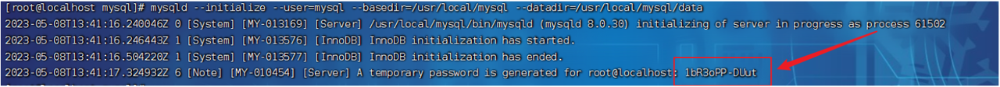

#### 启动MySQL

> **补充｜启动检查。** 启动服务后用 `systemctl status`、`ss -lntp` 和客户端连接分别验证进程、端口和登录链路，不要只看命令是否返回成功。

A. 启动MySQL服务

```shell
systemctl start mysql
```

B. 通过命令, 登录MySQL

```shell
#xxxxx 代表上述生成的root的临时密码
mysql -uroot -pxxxxx
```

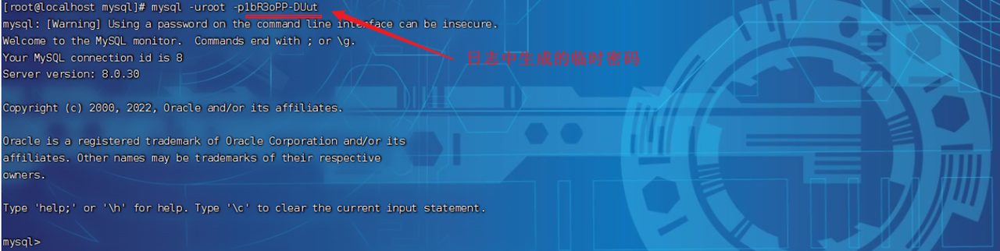

#### 配置MySQL

> **补充｜配置变更。** 修改 MySQL 配置后先检查语法和错误日志，再重启服务。涉及数据目录、字符集和用户权限的变更应安排维护窗口。

A. 修改root用户的密码

```shell
ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY '1234';
```

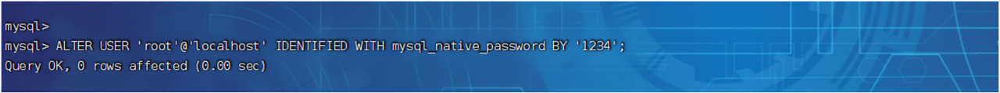

注意: 这个root账号仅仅能够在本机localhost上访问，我们在windows上是无法访问的。如果需要在window上或其他服务器上也能远程访问，需要创建一个账号，用于远程访问的。

B. 创建账号, 并授权远程访问

```shell
CREATE USER 'root'@'%' IDENTIFIED BY '1234';

GRANT ALL PRIVILEGES ON *.* TO 'root'@'%';

FLUSH PRIVILEGES;
```

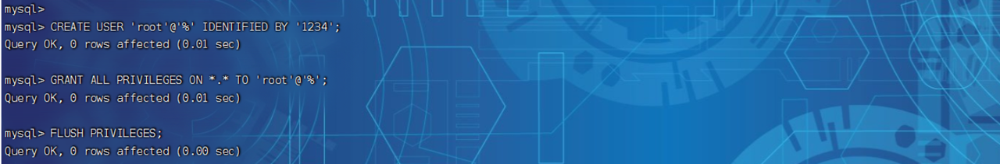

我们已经开启了MySQL的远程访问的权限，为什么还是连接不上MySQL服务器呢？？ 这是因为Linux系统的防火墙，将我们的访问拦截了。

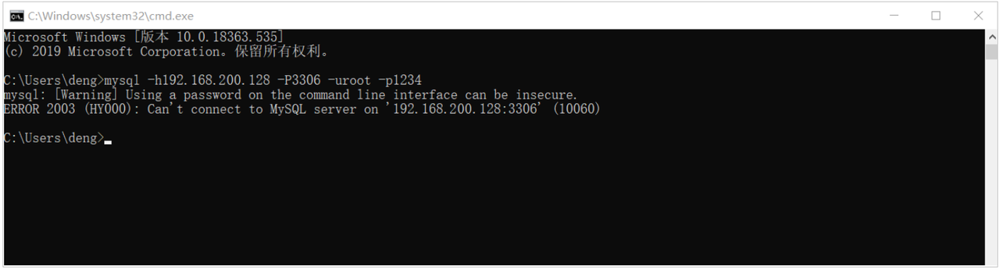

#### 防火墙操作

> **补充｜最小开放。** 防火墙只开放必要端口：SSH、HTTP/HTTPS，以及确有需要的数据库端口。数据库通常不应直接暴露到公网，应通过内网或应用层访问。

Linux系统安装完毕后，系统启动时，防火墙自动启动，防火墙拦截了所有端口的访问。接下来我们就需要学习一下，如何操作防火墙，具体指令如下：

> **讲义表格/演示内容**（原文以嵌入表格展示。）

注意： 要想在windows上能够访问MySQL，需要开放防火墙的3306端口  或者 直接关闭防火墙 ，执行如下指令:

```shell
#开发防火墙的3306端口号
firewall-cmd --zone=public --add-port=3306/tcp --permanent

#重新加载
firewall-cmd --reload

#查看开放的端口号
firewall-cmd --zone=public --list-ports
```

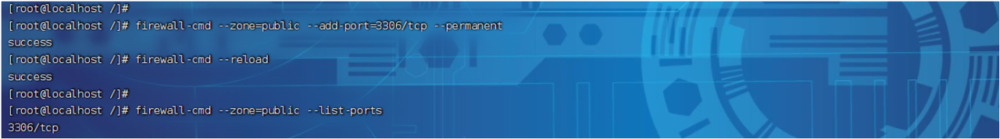

或者直接关闭防火墙:

```shell
systemctl stop firewalld
```

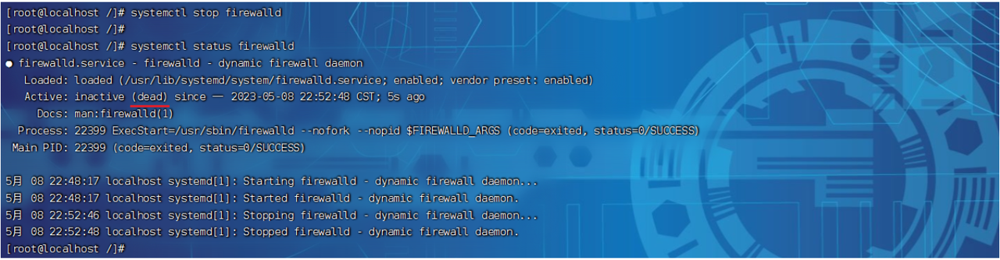

#### 连接测试

> **补充｜分层排障。** 连接失败时按 DNS/IP、端口、防火墙、账号权限、应用配置的顺序排查，先用 `ping` 或 `ss` 确认网络层，再检查服务层。

关闭掉linux系统的防火墙之后，我们就可以打开windows上的命令行，通过mysql的客户端(命令行/图形化界面)来连接远程linux上安装的MySQL数据库了。

1). 客户端连接

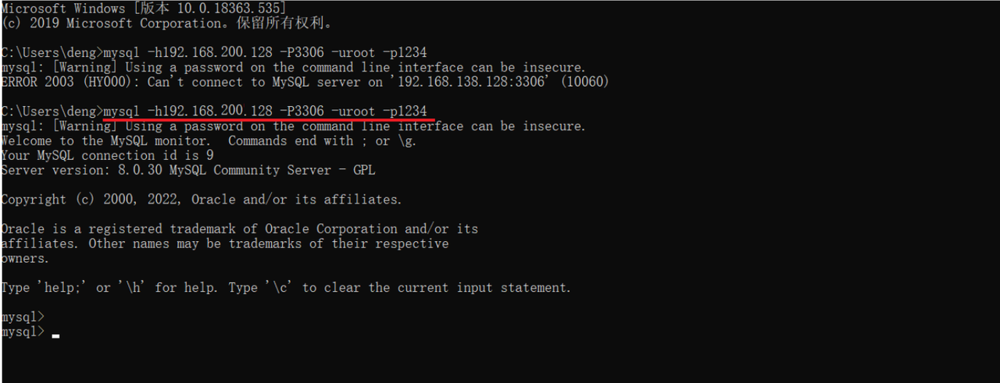

2). 打开DataGrip图形化工具连接

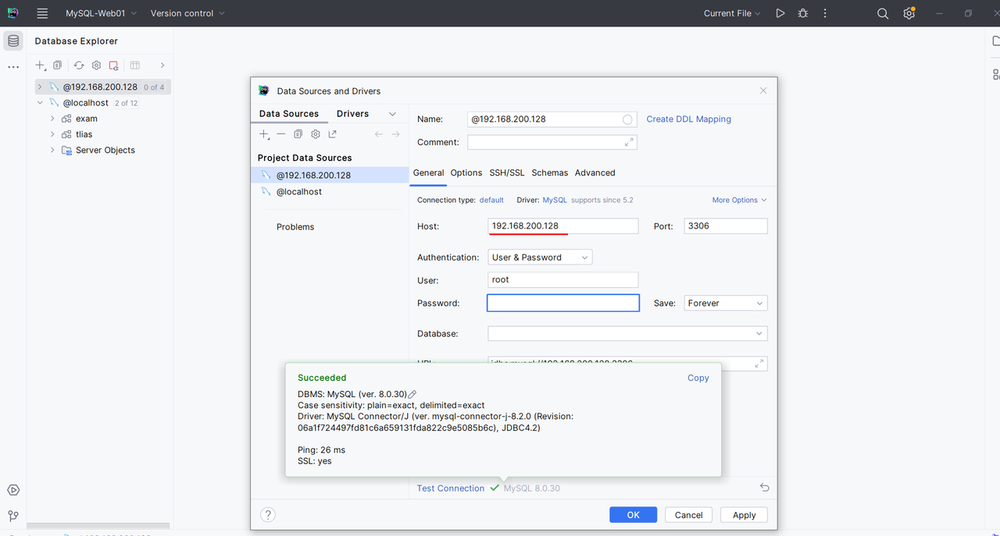

执行资料中提供的SQL脚本 tlias.sql 。

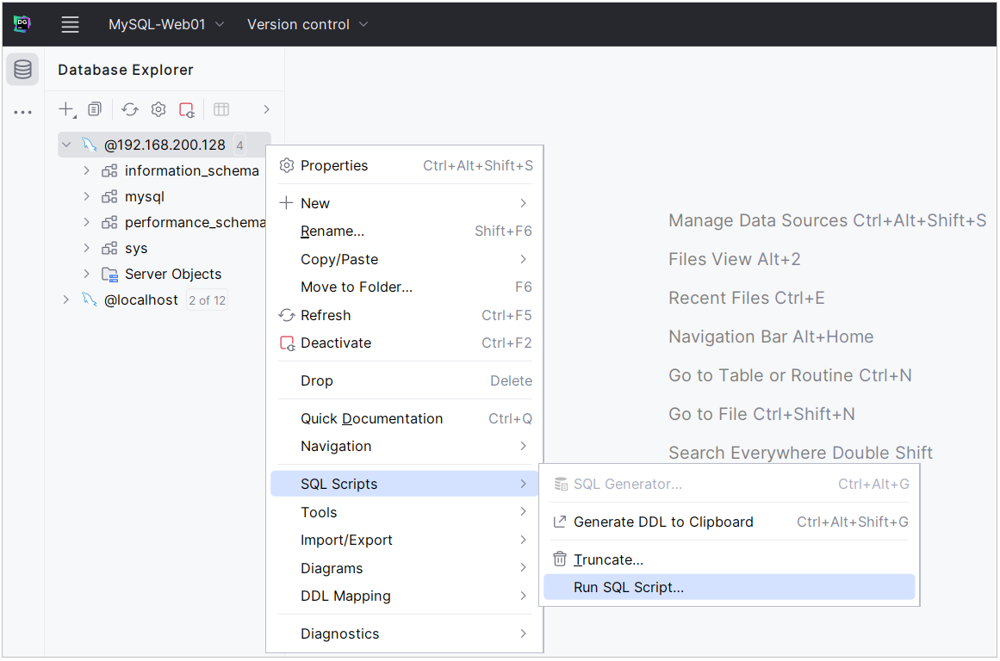

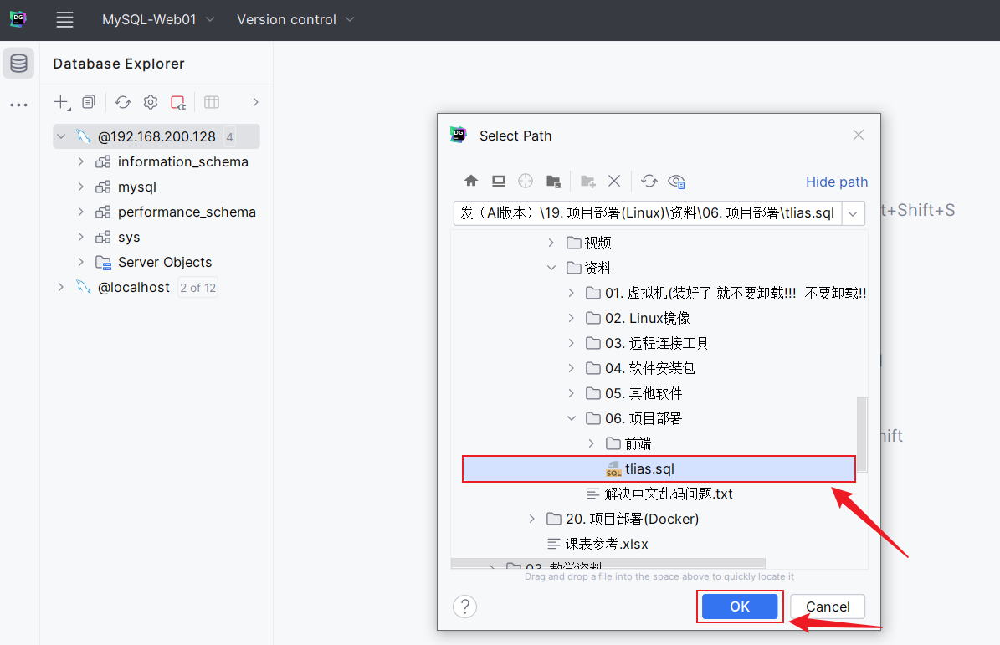

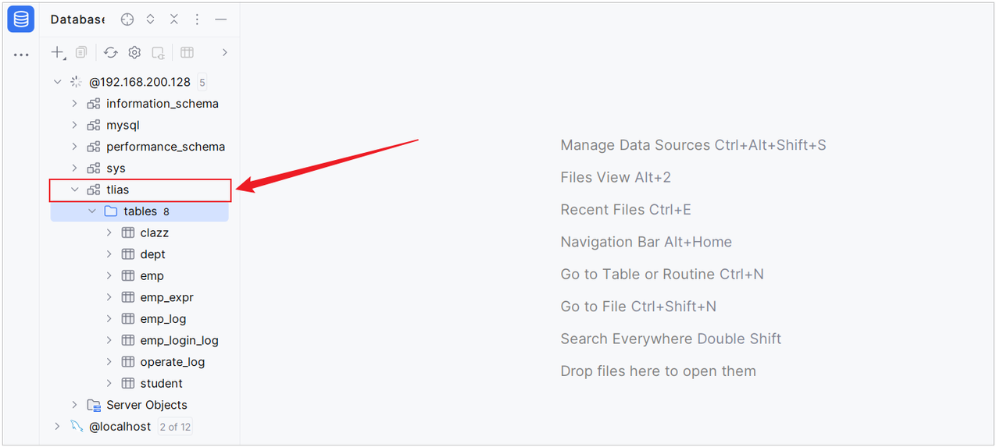

### 安装Nginx

> **补充｜静态与代理。** Nginx 既能托管前端静态资源，也能把 `/api` 请求代理到后端服务。配置文件修改后先执行 `nginx -t`，通过后再 reload。

#### 安装

Nginx的安装包，从官方下载下来的是c语言的源码包，我们需要自己编译安装。具体操作步骤如下：

1). 安装Nginx运行时需要的依赖

```shell
yum install -y pcre pcre-devel zlib zlib-devel openssl openssl-devel
```

安装C语言的编译环境.

```shell
yum install gcc-c++
```

2). 上传Nginx的源码包

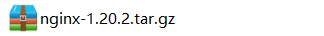

3). 解压源码包到当前目录

```shell
tar -zxvf nginx-1.20.2.tar.gz
```

4). 进入到解压目录后，执行指令

```shell
#进入解压目录
cd nginx-1.20.2

#执行命令配置, 生成Makefile文件
./configure --prefix=/usr/local/nginx
```

5). 执行命令进行编译和安装

```shell
#编译
make

#编译安装
make install
```

#### 启动Nginx

进入到nginx安装目录/usr/local/nginx，启动nginx服务

```shell
cd /usr/local/nginx/
sbin/nginx
```

启动完毕之后，我们可以通过 ps 指令查询当前系统中的nginx进程，从而确认nginx是否启动 。

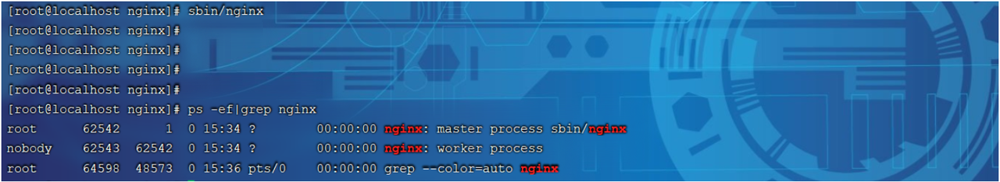

然后，我们就可以打开浏览器，访问服务器上的nginx 。

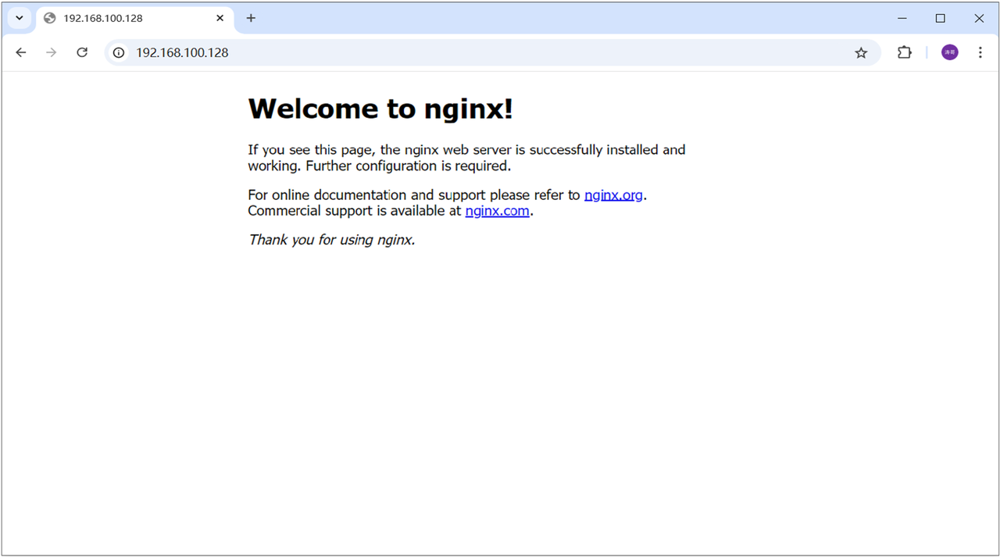

## 项目部署

> **补充｜部署顺序。** 先准备服务器和依赖，再部署数据库、后端、前端，最后进行端到端验收。每一步记录版本、路径、端口和回滚方式。

### 前端项目部署

> **补充｜构建配置。** 前端构建时确认生产 API 前缀、资源 base 路径和 history fallback；上传前检查 `dist` 中没有开发环境地址和敏感信息。

1). 将nginx的安装目录的html中的静态资源文件先删除掉。

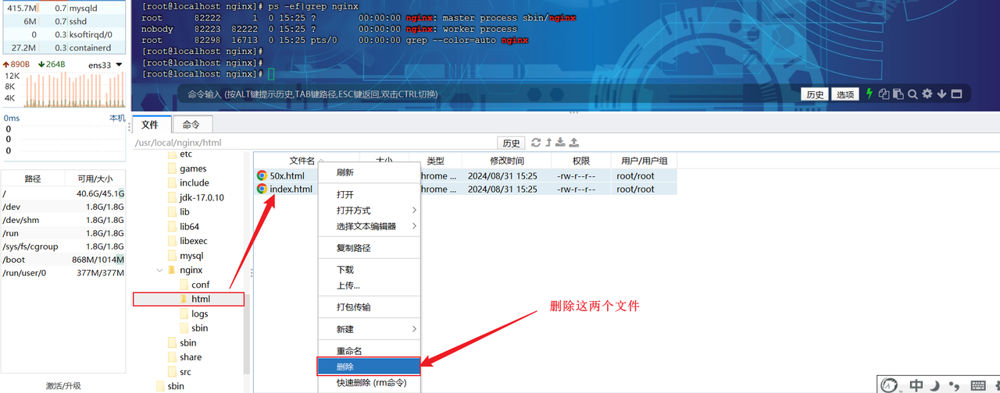

2). 将资料中提供的 "资料/06. 项目部署/前端/页面资源" 目录下的静态资源文件，全部上传到nginx安装目录下的 html 目录中.

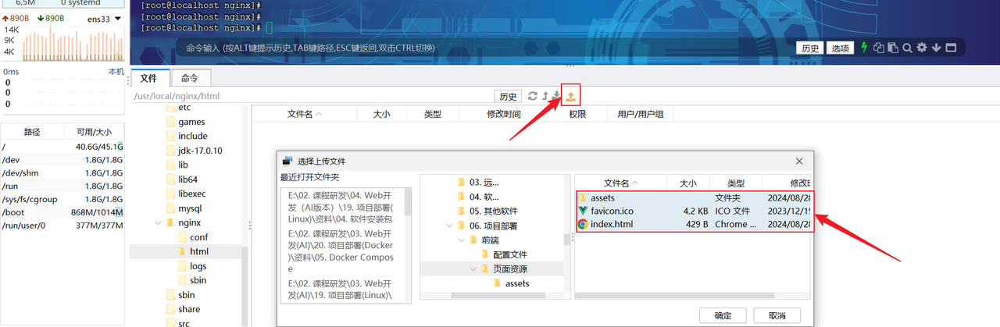

3). 修改资料中提供的 nginx.conf 配置文件，将其上传到nginx安装目录下的 conf 目录中.

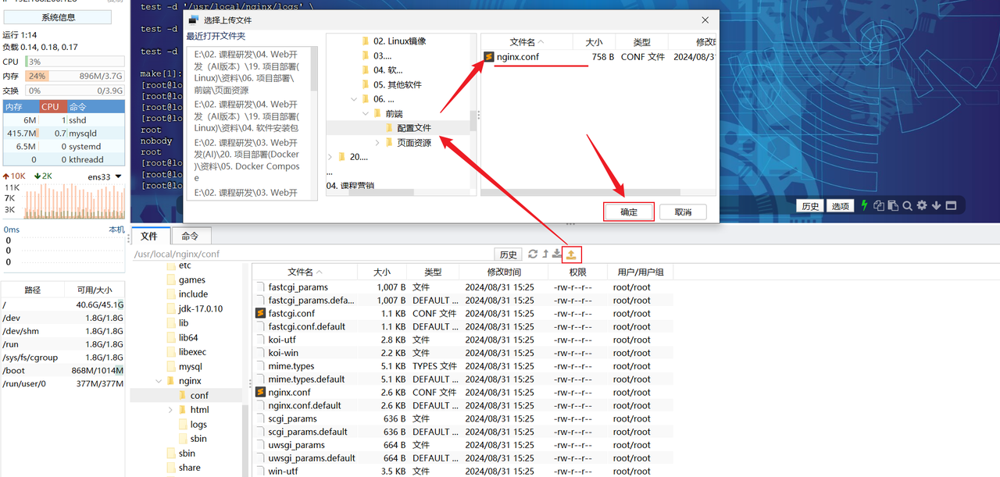

4). 重新加载nginx服务的配置文件

```shell
#重新加载配置文件
sbin/nginx -s reload
```

5). 再次访问nginx (可能会存在浏览器缓存, 可以按Ctrl+F5, 强制刷新清理缓存)

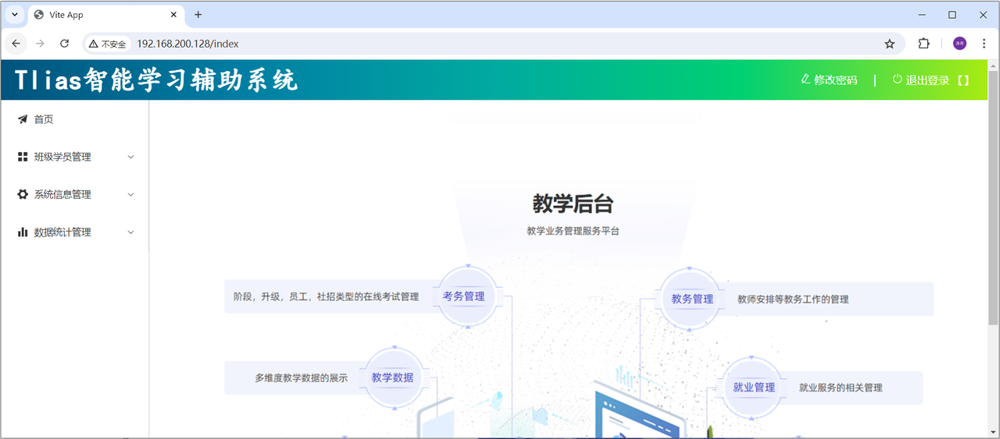

**讲义提示**

> nginx服务常见操作指令:

> - 启动: sbin/nginx

> - 重载: sbin/nginx -s reload

> - 停止: sbin/nginx -s stop

### 后端项目部署

> **补充｜进程管理。** `nohup` 适合快速后台运行，正式环境应进一步使用 systemd、Docker 或其他进程管理器，配置自动重启、日志轮转和健康检查。

之前我们讲解Linux操作系统时，就提到，我们服务端开发工程师学习Linux系统的目的就是将来我们开发的项目绝大部分情况下都需要部署在Linux系统中。

#### 环境准备

> **补充｜部署清单。** 部署前核对 JDK、MySQL、Nginx、端口、防火墙、数据库账号、OSS 密钥和目录权限，减少上线后才发现环境缺项。

那现在，项目要上线了，要部署到linux服务器上了，我们也需要使用linux服务器上所安装的mysql数据库。

那此时，我们就可以再准备一份文件 application.yml 将里面的配置的mysql的ip地址及相关配置信息修改一下（配置Linux上安装的MySQL的信息）：

```yaml
#配置数据库连接信息
spring:
  datasource:
    driver-class-name: com.mysql.cj.jdbc.Driver
    url: jdbc:mysql://192.168.100.128:3306/tlias
    username: root
    password: 1234
  servlet:
    multipart:
      max-file-size: 10MB #单个文件最大大小限制10MB
      max-request-size: 100MB #单个请求最大大小限制100MB

#配置mybatis的日志输出到控制台
mybatis:
  configuration:
    log-impl: org.apache.ibatis.logging.stdout.StdOutImpl
    #配置mybatis的驼峰命名的映射开关
    map-underscore-to-camel-case: true
#查看事务管理的日志
logging:
  level:
    org.springframework.jdbc.support.JdbcTransactionManager: debug

#阿里云oss配置
aliyun:
  oss:
    endpoint: https://oss-cn-beijing.aliyuncs.com
    bucketName: java422-web-ai
```

改造完毕之后，可以在本地的idea中先启动当前项目，然后访问一下，看看工程是否正常访问。

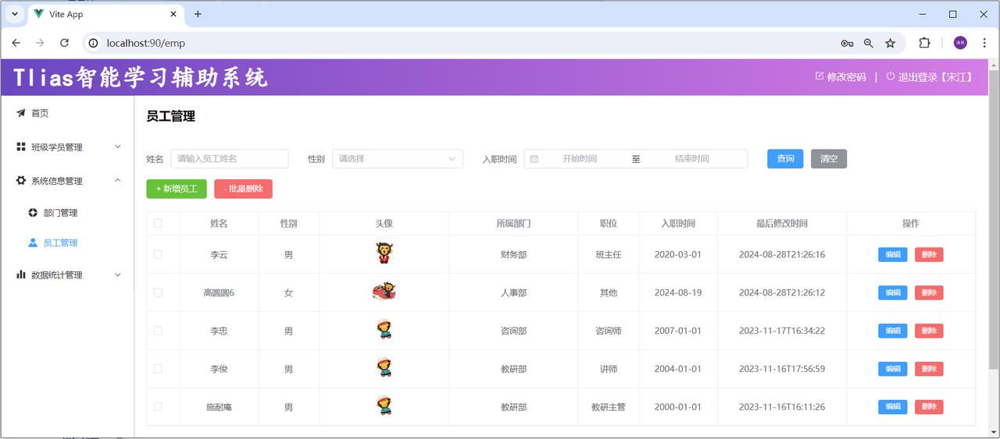

#### 打包部署

> **补充｜版本可追踪。** JAR、前端 dist 和配置文件使用带版本的目录或文件名，发布时保留上一版本，出现问题可以快速切换回滚。

1). 执行 package 指令，进行打包操作，将当前的springboot项目，打成一个jar包。 (跳过测试)

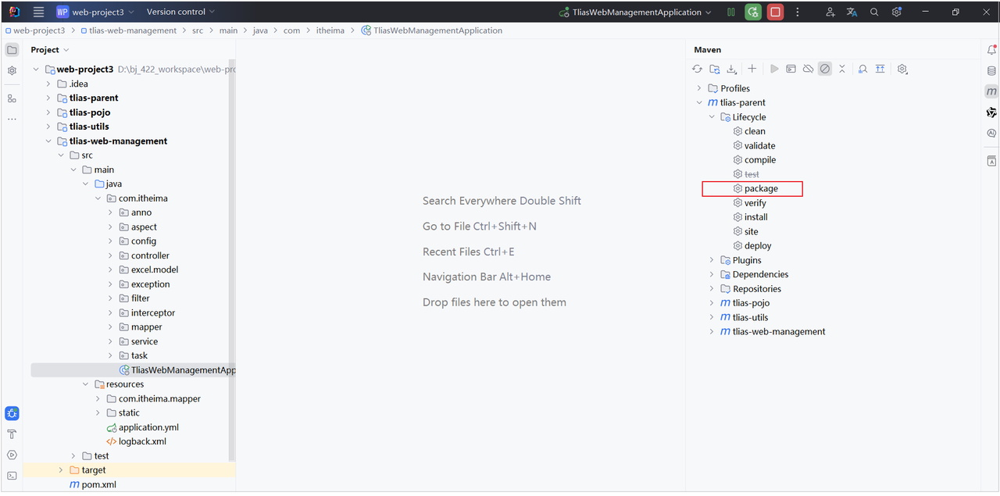

2). 在Linux服务器上创建一个目录，将jar包上传到服务器 。

```yaml
mkdir -p /usr/local/app
```

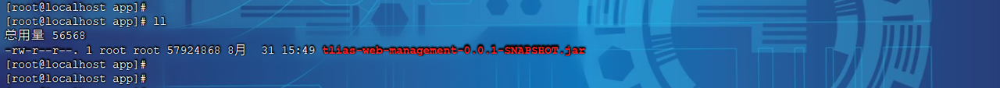

3). 通过java命令，启动项目

```yaml
#进入目录/usr/local/app 
cd /usr/local/app

#运行jar包
java -jar tlias-web-management-0.0.1-SNAPSHOT.jar
```

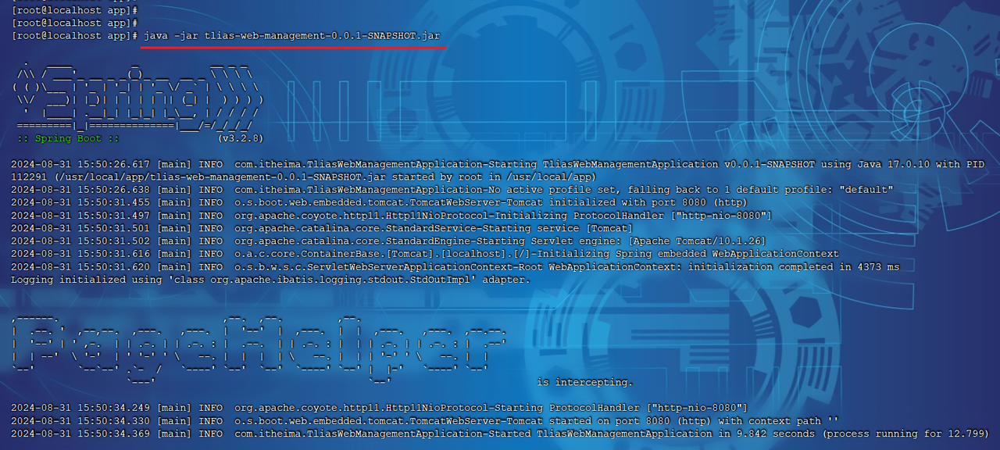

项目启动起来之后，就可以打开浏览器测试啦。

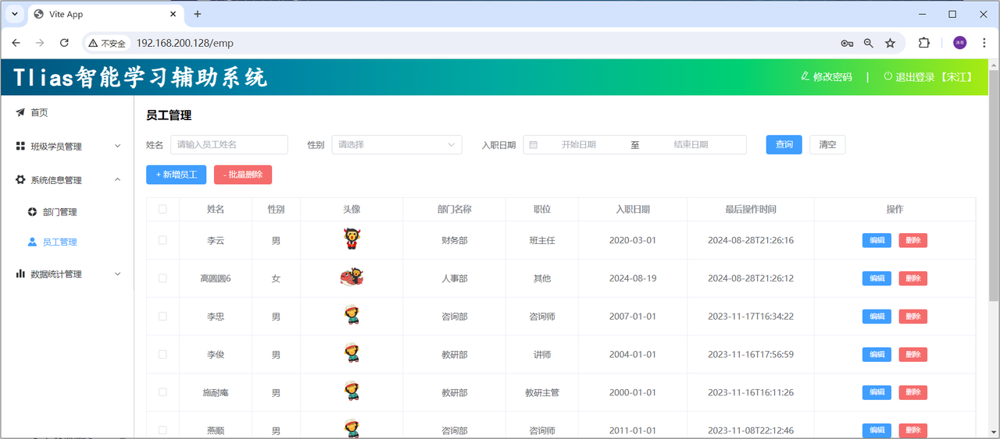

#### 阿里云OSS秘钥配置

> **补充｜密钥保护。** OSS AccessKey 不应写入 Git 或前端代码。使用环境变量、服务器密钥管理或受限 RAM 账号，并按最小权限配置 Bucket 访问策略。

由于在开发的时候，我们将访问阿里云OSS的AccessKeyId，AccessKeySecret都配置在了系统的环境变量中了。那现在项目部署到了Linux服务器中，调用阿里云OSS进行文件上传时，程序就会获取Linux系统中的环境变量。所以此时，我们需要将AccessKeyId，AccessKeySecret配置为Linux系统的环境变量。

1). 查看Windows系统之前配置的环境变量

```yaml
echo %OSS_ACCESS_KEY_ID%

echo %OSS_ACCESS_KEY_SECRET%
```

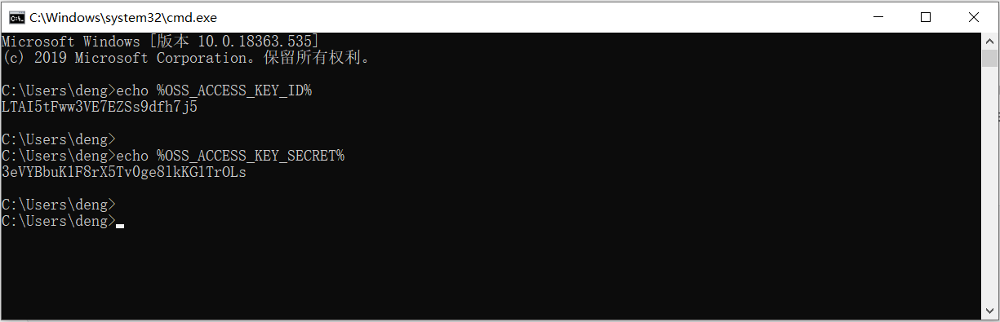

我们将上述自己的 AccessKeyId 与  AccessKeySecret 复制出来，然后在linux系统中配置环境变量。

2). 执行如下指令：

```yaml
echo "export OSS_ACCESS_KEY_ID=LTAI5tFww3VE7EZSs9dfh7j6" >> /etc/profile

echo "export OSS_ACCESS_KEY_SECRET=3eVYBbuK1F8rX5Tv0ge8lkKG1TrOL5" >> /etc/profile

source /etc/profile
```

注意!!!：上述的绿色背景部分，是自己的阿里云OSS账号的 OSS_ACCESS_KEY_ID， OSS_ACCESS_KEY_SECRET，一个字符都不能错，在记事本中将命令组装好，然后再到命令行中执行。

注意!!!：上述的绿色背景部分，是自己的阿里云OSS账号的 OSS_ACCESS_KEY_ID， OSS_ACCESS_KEY_SECRET，一个字符都不能错，在记事本中将命令组装好，然后再到命令行中执行。

注意!!!：上述的绿色背景部分，是自己的阿里云OSS账号的 OSS_ACCESS_KEY_ID， OSS_ACCESS_KEY_SECRET，一个字符都不能错，在记事本中将命令组装好，然后再到命令行中执行。

执行完毕后，将finalShell的窗口关闭掉，重新打开一个新窗口（让环境变量生效），重新运行项目测试。

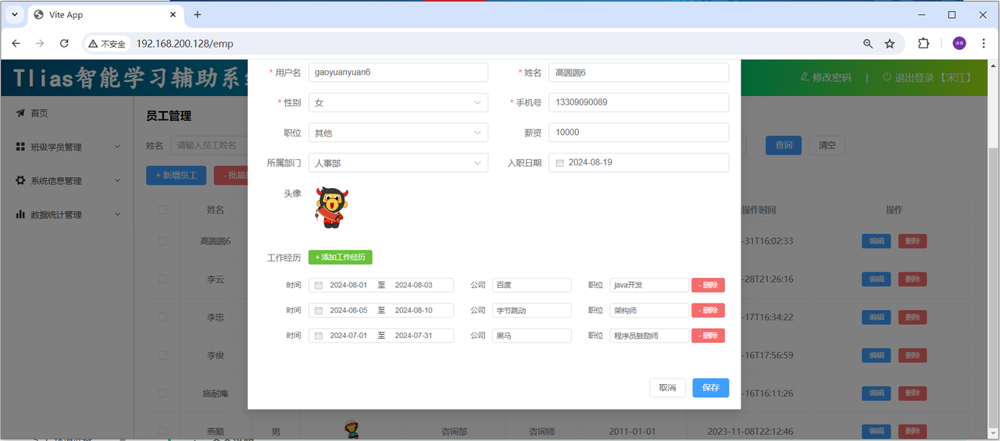

当前程序中存在的问题:

- 线上程序不会采用控制台霸屏的形式运行程序，而是将程序在后台运行

- 线上程序不会将日志输出到控制台，而是输出到日志文件，方便运维查阅信息

要解决上述这两个问题，我们就可以通过 nohup 指令让程序在后台运行。

#### 后台运行

> **补充｜日志与退出码。** 后台启动时把 stdout/stderr 重定向到明确日志文件，记录 PID 和启动命令；发布后检查进程、端口、日志和接口健康状态。

1). 后台运行程序

```yaml
nohup java -jar tlias-web-management-0.0.1-SNAPSHOT.jar &> tlias.log &
```

通过上述指令就可以后台运行服务，服务运行之后， 所有的日志信息都会输出到 tlias.log 文件中。

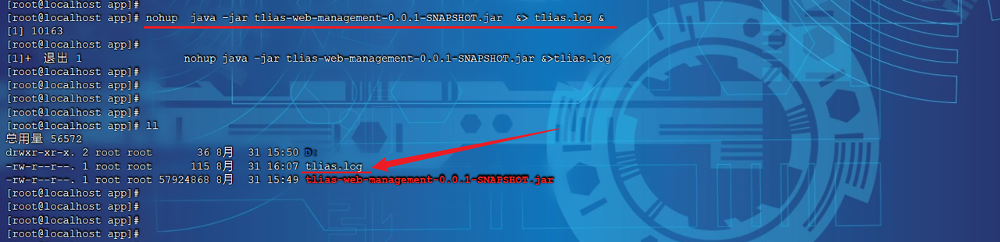

2). 停止服务

```yaml
#查看服务的进程信息
ps -ef|grep tlias

#杀掉进程
kill -9 xxxxx
```

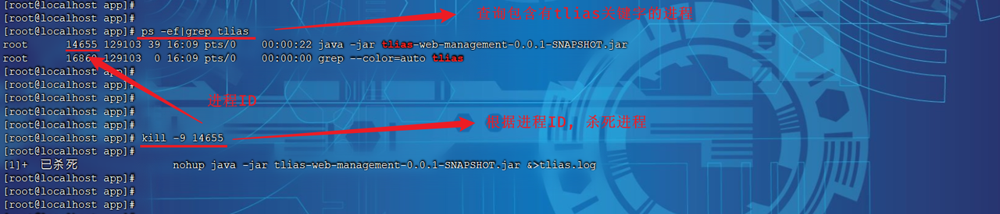

**讲义提示**

> nohup命令说明:

> - nohup命令：英文全称 no hang up（不挂起），用于不挂断地运行指定命令，退出终端不会影响程序的运行

> - 语法格式： nohup command [ args … ] [&]

> - 参数说明：

> - command：要执行的命令

> - args：一些参数，可以指定输出文件

> - &：让命令在后台运行

> - 举例：

> - nohup java -jar boot工程.jar &> hello.log &

> 上述指令的含义为： 后台运行 java -jar 命令，并将日志输出到hello.log文件

## 复习速查与验收（补充）

| 知识点 | 记忆要点 | 常见误区 |
| --- | --- | --- |
| Linux 目录 | `/etc` 配置、`/var/log` 日志、`/home` 用户目录、`/opt` 应用目录 | 所有文件都放在当前目录或 root 目录 |
| 文件命令 | `ls`、`cd`、`mkdir`、`rm`、`cp`、`mv` 配合路径完成操作 | 未确认 `pwd` 就执行删除或覆盖 |
| Vim | 插入、普通、命令三种模式切换 | 在普通模式直接输入文本或忘记保存 |
| 查找排障 | `find` 找文件，`grep` 找内容，`tail -f` 看实时日志 | 只看终端最后一行，不查完整日志 |
| JDK | `JAVA_HOME`、`PATH` 与实际版本一致 | 服务器上存在多个 JDK 却未确认启动版本 |
| MySQL | 服务、端口、账号权限和字符集都要验证 | 直接开放 3306 到公网 |
| Nginx | 静态托管、history 回退、`/api` 反向代理 | 只配置静态文件，接口请求仍指向本地地址 |
| 后台运行 | 日志、PID、端口和自动重启策略 | `nohup` 启动后不检查进程和错误日志 |
| 密钥管理 | OSS 等密钥放在环境变量或密钥管理系统 | 把 AccessKey 写进代码或提交到 Git |

### 跟练验收

1. 通过 FinalShell 登录 Linux，确认当前用户、主机名、IP 和工作目录。
2. 使用目录、文件、拷贝、移动、打包和查找命令完成一次文件整理，并核对结果。
3. 用 Vim 修改一个配置文件，保存退出后用 `grep` 或 `cat` 验证内容。
4. 安装并启动 JDK、MySQL、Nginx，分别验证版本、服务状态和监听端口。
5. 配置防火墙，仅开放必要端口，确认 SSH、HTTP/HTTPS 和应用接口按预期可达。
6. 构建前端并上传 `dist`，通过 Nginx 访问首页，刷新 history 路由不返回 404。
7. 打包后端 JAR，配置数据库和 OSS 环境变量，后台启动后检查 PID、端口和日志。
8. 通过浏览器完成登录、员工查询和图片上传，确认前后端、MySQL、OSS 链路打通。
9. 保存上一版本部署包，演练一次回滚或至少确认回滚文件和命令可用。

### 自测问题

- `/etc`、`/var/log`、`/home` 和 `/opt` 分别适合存放什么？
- `rm -r` 和 `rm -f` 的风险是什么，生产环境如何降低误删概率？
- `find` 与 `grep` 在排障中的职责有什么区别？
- 修改 Nginx 配置后为什么要先执行 `nginx -t` 再 reload？
- 前端 history 路由部署时为什么需要回退到 `index.html`？
- 为什么不应把 MySQL 和 OSS 密钥直接写进项目代码？
- `nohup` 启动的后端进程如何确认它真的在运行并能被监控？